
# STRATUM — Sheet-Resistance Virtual Metrology

## Phase 3 — Step 3.6

### Background

Previous STRATUM investigations established
a virtual metrology model for mean film thickness.

Exploratory analysis and statistical hypothesis
testing demonstrated the importance of monitoring
additional material properties.

This investigation develops an independent
virtual metrology model for mean sheet resistance.

### Objectives

1. Establish resistance-specific historical baselines.

2. Compare bounded Ridge, Random Forest, and
   XGBoost regression models.

3. Evaluate candidates using the established
   chronological expanding-window CV framework.

4. Investigate equipment metadata and missing-value
   preprocessing strategies.

5. Implement training-fitted target standardisation.

6. Apply training-internal XGBoost early stopping.

7. Freeze a resistance-model configuration before
   original-validation assessment.

### Target

mean_resistance

### Input Restrictions

Only candidate APC variables and optional equipment
metadata are permitted as predictive inputs.

Measured thickness, measured resistance,
derived resistivity, and quality classifications
are excluded from the predictor set.

### Target Standardisation

Resistance values have a substantially smaller
numerical magnitude than thickness values.

ML candidates therefore use a target transformer
fitted exclusively on the relevant training targets.

Predictions are inverse-transformed into the
original dataset scale before evaluation.

### Evaluation Protocol

Use the original training partition and the
same five chronological cross-validation folds
established in Step 3.5.

Prevent lot and batch overlap within folds.

Reserve the original validation partition for
post-selection assessment.

The final held-out test partition remains reserved.

### Primary Metric

Mean chronological cross-validation MAE,
expressed in the original dataset target scale.

Additional diagnostics include RMSE, R2, MAPE,
signed bias, prediction plausibility, model size,
and inference latency.

In [1]:

# Imports and experiment configuration

from pathlib import Path
import sys
import json
import hashlib
import time
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import xgboost

from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

current_dir = Path.cwd()

if (
    current_dir
    / "ml"
    / "resistance_models.py"
).exists():

    project_root = current_dir

elif (
    current_dir.parent
    / "ml"
    / "resistance_models.py"
).exists():

    project_root = current_dir.parent

else:

    raise FileNotFoundError(
        "Cannot locate STRATUM project root."
    )

if str(project_root) not in sys.path:

    sys.path.insert(
        0,
        str(project_root),
    )

from ml.data_split import chronological_lot_split

from ml.preprocessing import get_feature_columns

from ml.evaluation import (
    evaluate_regression,
    calculate_mae_improvement,
)

from ml.cross_validation import (
    prepare_chronological_data,
    purge_training_overlap,
    chronological_cv_folds,
)

from ml.resistance_models import (
    get_resistance_candidate_columns,
    fit_resistance_candidate,
    get_fitted_resistance_pipeline,
)

TARGET = "mean_resistance"

RANDOM_STATE = 42

N_SPLITS = 5

INITIAL_TRAIN_FRACTION = 0.4

INNER_VALIDATION_FRACTION = 0.2

EARLY_STOPPING_ROUNDS = 50

N_JOBS = -1

DISPLAY_SCALE = 1_000_000

print("STRATUM - Sheet Resistance Prediction")

print("Python:", sys.version.split()[0])

print("Scikit-learn:", sklearn.__version__)

print("XGBoost:", xgboost.__version__)

print("\nAll modules imported successfully!")

STRATUM - Sheet Resistance Prediction
Python: 3.14.3
Scikit-learn: 1.9.1
XGBoost: 3.4.1

All modules imported successfully!


## 1. Dataset and Fold Reproducibility

Verify the original dataset fingerprint, APC
feature schema, and fixed dataset partitions.

Reproduce the exact chronological cross-validation
folds used for thickness-model optimisation.

Restrict resistance-model development to
the original training partition.

In [2]:

# Load and verify original dataset

csv_path = (
    project_root
    / "data"
    / "raw"
    / "apc_spc_AlCu_inputs_outputs.csv"
)

manifest = json.loads(
    (
        project_root
        / "docs"
        / "split_manifest.json"
    ).read_text(encoding="utf-8")
)

current_sha256 = hashlib.sha256(
    csv_path.read_bytes()
).hexdigest()

assert (
    current_sha256
    == manifest["dataset_sha256"]
)

df = pd.read_csv(
    csv_path,
    sep=";",
    skiprows=1,
    low_memory=False,
)

assert df.shape == (5208, 178)

train_df, val_df, test_df, split_info = (
    chronological_lot_split(
        df,

        test_fraction=manifest[
            "test_fraction"
        ],

        validation_fraction=manifest[
            "validation_fraction_of_development"
        ],
    )
)

assert (
    split_info
    == manifest["split_summary"]
)

apc_features, _ = get_feature_columns(df)

assert (
    apc_features
    == manifest["numeric_apc_features"]
)

train_df = prepare_chronological_data(
    train_df
)

val_df = prepare_chronological_data(
    val_df
)

assert len(train_df) == 3331
assert len(val_df) == 834
assert len(test_df) == 1042

assert len(apc_features) == 110

assert np.isfinite(
    train_df[TARGET]
).all()

assert (
    train_df[TARGET] > 0
).all()

print("Dataset fingerprint: VERIFIED")

print("Partition manifest: VERIFIED")

print("APC feature schema: VERIFIED")

print("\nTraining records:", len(train_df))

print("Validation records:", len(val_df))

print("Reserved test records:", len(test_df))

Dataset fingerprint: VERIFIED
Partition manifest: VERIFIED
APC feature schema: VERIFIED

Training records: 3331
Validation records: 834
Reserved test records: 1042


In [3]:

# Load the established thickness experiment

results_dir = (
    project_root
    / "ml"
    / "results"
)

thickness_optimisation = json.loads(
    (
        results_dir
        / "thickness_optimisation.json"
    ).read_text(encoding="utf-8")
)

thickness_selection = json.loads(
    (
        results_dir
        / "thickness_model_selection.json"
    ).read_text(encoding="utf-8")
)

assert (
    thickness_optimisation["dataset_sha256"]
    == current_sha256
)

assert (
    thickness_selection["dataset_sha256"]
    == current_sha256
)

assert (
    thickness_optimisation["cv_folds"]
    == N_SPLITS
)

assert (
    thickness_optimisation[
        "initial_train_fraction"
    ]
    == INITIAL_TRAIN_FRACTION
)

assert (
    thickness_optimisation[
        "inner_validation_fraction"
    ]
    == INNER_VALIDATION_FRACTION
)

assert (
    thickness_optimisation[
        "early_stopping_rounds"
    ]
    == EARLY_STOPPING_ROUNDS
)

assert (
    thickness_optimisation["selection"]
    == thickness_selection
)

print("Previous thickness experiment: VERIFIED")

print(
    "\nFrozen thickness candidate:",
    thickness_selection[
        "selected_candidate"
    ]["name"]
)

print(
    "Thickness mean CV MAE:",
    thickness_selection[
        "selected_mean_cv_mae"
    ]
)

print(
    "Thickness boosting rounds:",
    thickness_selection[
        "selected_candidate"
    ]["parameters"]["n_estimators"]
)

Previous thickness experiment: VERIFIED

Frozen thickness candidate: XGB-4
Thickness mean CV MAE: 1.2092899217275688
Thickness boosting rounds: 820


In [4]:

# Reproduce the same chronological CV folds

folds = chronological_cv_folds(
    train_df,

    n_splits=N_SPLITS,

    initial_train_fraction=(
        INITIAL_TRAIN_FRACTION
    ),
)

fold_summary = [
    fold["info"]
    for fold in folds
]

# Require exact consistency with Notebook 13.

assert (
    fold_summary
    == thickness_optimisation["fold_summary"]
)

all_cv_validation_ids = []

for fold in folds:

    fold_train = fold["train"]

    fold_val = fold["validation"]

    assert (
        fold_train["runstart"].max()
        < fold_val["runstart"].min()
    )

    for column in [
        "wafer_id",
        "lot",
        "bat_id",
    ]:

        assert set(
            fold_train[column]
        ).isdisjoint(
            set(fold_val[column])
        )

    all_cv_validation_ids.extend(
        fold_val["wafer_id"].tolist()
    )

assert len(
    all_cv_validation_ids
) == 1995

assert len(
    set(all_cv_validation_ids)
) == 1995

assessment_train_df, assessment_purge_info = (
    purge_training_overlap(
        train_df,
        val_df,
    )
)

assert (
    assessment_purge_info
    == thickness_optimisation[
        "assessment_purge_info"
    ]
)

display(
    pd.DataFrame(fold_summary)[
        [
            "fold",
            "training_records",
            "validation_records",
            "purged_records",
            "validation_start",
            "validation_end",
        ]
    ]
)

print(
    "\nResistance folds match thickness folds: PASSED"
)

print(
    "Original-validation training records:",
    len(assessment_train_df)
)

,fold,training_records,validation_records,purged_records,validation_start,validation_end
0,1,1334,399,2,2022-09-08 17:40:07,2023-01-05 07:34:27
1,2,1734,399,1,2023-01-05 07:35:58,2023-04-27 23:00:49
2,3,2133,399,1,2023-04-27 23:02:42,2023-07-16 15:48:28
3,4,2531,399,2,2023-07-16 15:50:54,2023-10-03 16:46:30
4,5,2931,399,1,2023-10-03 16:47:48,2023-12-26 05:13:18



Resistance folds match thickness folds: PASSED
Original-validation training records: 3331


## 2. Resistance Target Characterisation

Investigate the numerical distribution of
mean sheet resistance in the training partition.

Verify the target-standardisation procedure
and its inverse transformation.

Investigate chronological changes in the target
distribution across training and validation folds.

Do not use original-validation or final-test
targets to choose preprocessing parameters.

In [5]:

# Training resistance target statistics

target_summary = (
    train_df[TARGET]
    .describe()
    .to_frame("Mean Resistance")
)

display(
    target_summary.round(10)
)

target_values = (
    train_df[TARGET]
    .to_numpy(dtype=float)
    .reshape(-1, 1)
)

diagnostic_scaler = StandardScaler()

standardised_target = (
    diagnostic_scaler.fit_transform(
        target_values
    )
)

reconstructed_target = (
    diagnostic_scaler.inverse_transform(
        standardised_target
    )
)

np.testing.assert_allclose(
    reconstructed_target,
    target_values,
    rtol=1e-12,
    atol=1e-15,
)

print(
    "Original target mean:",
    target_values.mean()
)

print(
    "Original target standard deviation:",
    target_values.std()
)

print(
    "Standardised target mean:",
    standardised_target.mean()
)

print(
    "Standardised target standard deviation:",
    standardised_target.std()
)

print(
    "\nInverse target transformation: PASSED"
)

,Mean Resistance
count,3331.000000
mean,0.002894
std,0.000053
min,0.002705
25%,0.002861
50%,0.002889
75%,0.002922
max,0.003223


Original target mean: 0.002894437509841971
Original target standard deviation: 5.3341696885906705e-05
Standardised target mean: 5.955674927175622e-15
Standardised target standard deviation: 1.0

Inverse target transformation: PASSED


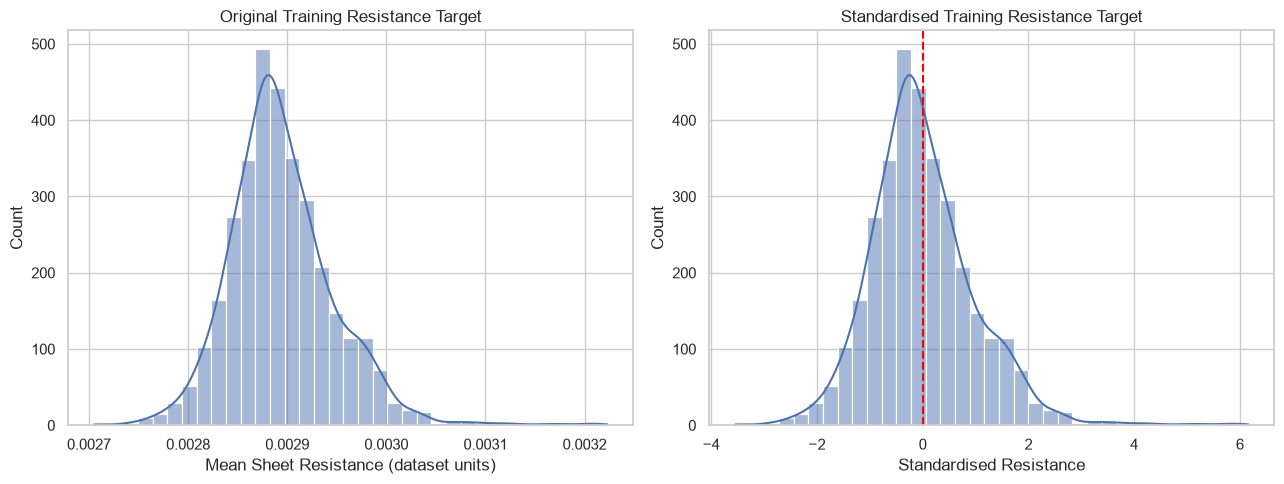

In [6]:

# Visualise original and standardised target

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
)

sns.histplot(
    target_values.ravel(),
    bins=35,
    kde=True,
    ax=axes[0],
)

axes[0].set_title(
    "Original Training Resistance Target"
)

axes[0].set_xlabel(
    "Mean Sheet Resistance (dataset units)"
)

sns.histplot(
    standardised_target.ravel(),
    bins=35,
    kde=True,
    ax=axes[1],
)

axes[1].set_title(
    "Standardised Training Resistance Target"
)

axes[1].set_xlabel(
    "Standardised Resistance"
)

axes[1].axvline(
    0,
    color="red",
    linestyle="--",
)

plt.tight_layout()
plt.show()

,Fold,Partition,Records,Mean,Median,Std,Minimum,Maximum
0,1,Train,1334,0.002880,0.002877,0.000046,0.002713,0.003064
1,1,Validation,399,0.002892,0.002886,0.000050,0.002705,0.003074
2,2,Train,1734,0.002883,0.002878,0.000047,0.002705,0.003074
3,2,Validation,399,0.002900,0.002895,0.000053,0.002772,0.003124
4,3,Train,2133,0.002886,0.002881,0.000049,0.002705,0.003124
5,3,Validation,399,0.002909,0.002898,0.000068,0.002763,0.003210
6,4,Train,2531,0.002890,0.002883,0.000053,0.002705,0.003210
7,4,Validation,399,0.002909,0.002903,0.000056,0.002743,0.003223
8,5,Train,2931,0.002892,0.002886,0.000054,0.002705,0.003223
9,5,Validation,399,0.002911,0.002904,0.000048,0.002809,0.003087


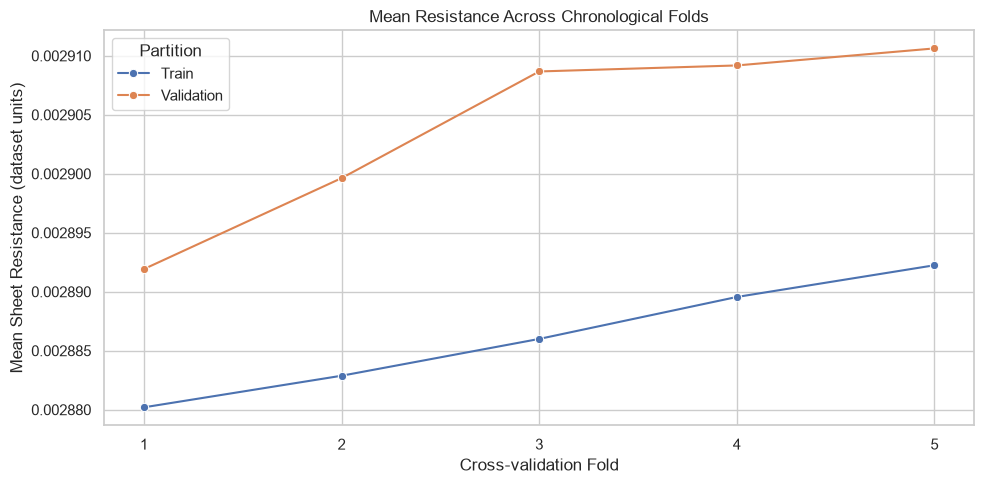

In [7]:

# Fold-specific resistance distribution diagnostics

target_fold_rows = []

for fold in folds:

    for partition in [
        "train",
        "validation",
    ]:

        values = fold[partition][TARGET]

        target_fold_rows.append({
            "Fold": fold["fold"],

            "Partition": partition.title(),

            "Records": len(values),

            "Mean": float(values.mean()),

            "Median": float(values.median()),

            "Std": float(values.std()),

            "Minimum": float(values.min()),

            "Maximum": float(values.max()),
        })

target_fold_summary = pd.DataFrame(
    target_fold_rows
)

display(
    target_fold_summary.round(10)
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=target_fold_summary,

    x="Fold",

    y="Mean",

    hue="Partition",

    marker="o",

    errorbar=None,
)

plt.xticks(
    range(1, N_SPLITS + 1)
)

plt.title(
    "Mean Resistance Across Chronological Folds"
)

plt.xlabel("Cross-validation Fold")

plt.ylabel(
    "Mean Sheet Resistance (dataset units)"
)

plt.tight_layout()
plt.show()

## 3. Predefined Resistance Candidate Configurations

Evaluate three historical baselines and ten
machine learning configurations.

Candidate parameters are informed by the preceding
thickness-model experiments.

All ML candidates use training-fitted
target standardisation.

The search space is fixed before executing
resistance-model cross-validation.

Resistance-specific boosting rounds are
selected through internal chronological
early stopping.

In [8]:

# Define resistance-model candidates

candidates = []


def add_candidate(
    name,
    algorithm,
    include_equipment,
    **parameters,
):

    candidates.append({
        "name": name,
        "algorithm": algorithm,
        "include_equipment": include_equipment,
        "parameters": parameters,
    })


# Historical baselines

add_candidate(
    "Global Mean",
    "Global Mean",
    False,
)

add_candidate(
    "Global Median",
    "Global Median",
    False,
)

add_candidate(
    "Equipment Mean",
    "Equipment Mean",
    True,
)


# Bounded Ridge

for name, equipment in [
    ("RES-Ridge-1", False),
    ("RES-Ridge-2", True),
]:

    add_candidate(
        name,
        "Ridge",
        equipment,

        alpha=10.0,

        clip_z=5.0,
    )


# Random Forest

for name, equipment in [
    ("RES-RF-1", False),
    ("RES-RF-2", True),
]:

    add_candidate(
        name,
        "Random Forest",
        equipment,

        n_estimators=200,

        max_depth=None,

        min_samples_leaf=1,

        max_features=0.7,

        random_state=RANDOM_STATE,
    )


# XGBoost
#
# Fields:
# Name, equipment, missing strategy,
# depth, learning rate, maximum rounds,
# minimum child weight, L1, L2.

xgb_search_space = [
    (
        "RES-XGB-1", False, "median",
        4, 0.025, 1500, 5, 0.1, 5.0,
    ),
    (
        "RES-XGB-2", True, "median",
        4, 0.025, 1500, 5, 0.1, 5.0,
    ),
    (
        "RES-XGB-3", False, "native",
        4, 0.025, 1500, 5, 0.1, 5.0,
    ),
    (
        "RES-XGB-4", True, "native",
        4, 0.025, 1500, 5, 0.1, 5.0,
    ),
    (
        "RES-XGB-5", False, "median",
        3, 0.05, 1200, 3, 0.1, 3.0,
    ),
    (
        "RES-XGB-6", True, "median",
        5, 0.05, 1000, 5, 0.1, 5.0,
    ),
]

for (
    name,
    equipment,
    missing_strategy,
    depth,
    learning_rate,
    rounds,
    child_weight,
    reg_alpha,
    reg_lambda,
) in xgb_search_space:

    add_candidate(
        name,
        "XGBoost",
        equipment,

        missing_strategy=missing_strategy,

        max_depth=depth,

        learning_rate=learning_rate,

        n_estimators=rounds,

        min_child_weight=child_weight,

        reg_alpha=reg_alpha,

        reg_lambda=reg_lambda,

        subsample=0.8,

        colsample_bytree=0.8,

        gamma=0.0,

        random_state=RANDOM_STATE,
    )

candidate_lookup = {
    candidate["name"]: candidate

    for candidate in candidates
}

BASELINE_ALGORITHMS = {
    "Global Mean",
    "Global Median",
    "Equipment Mean",
}

assert len(candidates) == 13

assert len(candidate_lookup) == 13

display(
    pd.json_normalize(candidates)
)

print(
    "Total resistance candidates:",
    len(candidates)
)

print(
    "Planned candidate-fold evaluations:",
    len(candidates) * len(folds)
)

,name,algorithm,include_equipment,parameters.alpha,parameters.clip_z,parameters.n_estimators,parameters.max_depth,parameters.min_samples_leaf,parameters.max_features,parameters.random_state,parameters.missing_strategy,parameters.learning_rate,parameters.min_child_weight,parameters.reg_alpha,parameters.reg_lambda,parameters.subsample,parameters.colsample_bytree,parameters.gamma
0,Global Mean,Global Mean,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Global Median,Global Median,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Equipment Mean,Equipment Mean,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,RES-Ridge-1,Ridge,False,10.0,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,RES-Ridge-2,Ridge,True,10.0,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,RES-RF-1,Random Forest,False,NaN,NaN,200.0,NaN,1.0,0.7,42.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,RES-RF-2,Random Forest,True,NaN,NaN,200.0,NaN,1.0,0.7,42.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,RES-XGB-1,XGBoost,False,NaN,NaN,1500.0,4.0,NaN,NaN,42.0,median,0.025,5.0,0.1,5.0,0.8,0.8,0.0
8,RES-XGB-2,XGBoost,True,NaN,NaN,1500.0,4.0,NaN,NaN,42.0,median,0.025,5.0,0.1,5.0,0.8,0.8,0.0
9,RES-XGB-3,XGBoost,False,NaN,NaN,1500.0,4.0,NaN,NaN,42.0,native,0.025,5.0,0.1,5.0,0.8,0.8,0.0


Total resistance candidates: 13
Planned candidate-fold evaluations: 65


## 4. Model Integration and Target-Scaling Verification

Verify that all candidate inputs exclude
measured metrology targets and quality labels.

Fit a bounded Ridge resistance candidate
using the first chronological training fold.

Verify automatic inverse transformation and
training-only target standardisation.

In [9]:

# Verify predictive input restrictions

allowed_inputs = set(apc_features) | {
    "equipment"
}

for candidate in candidates:

    columns = get_resistance_candidate_columns(
        candidate,
        apc_features,
    )

    assert set(columns).issubset(
        allowed_inputs
    )

    assert TARGET not in columns

    assert "mean_thickness" not in columns

    assert "quality_overall" not in columns

print("All candidate input checks: PASSED")


# Test a resistance pipeline

smoke_candidate = candidate_lookup[
    "RES-Ridge-1"
]

smoke_train = folds[0]["train"]

smoke_val = folds[0]["validation"].iloc[:10]

smoke_columns = (
    get_resistance_candidate_columns(
        smoke_candidate,
        apc_features,
    )
)

smoke_model, smoke_fit_info = (
    fit_resistance_candidate(
        candidate=smoke_candidate,

        training_data=smoke_train,

        apc_features=apc_features,

        target=TARGET,

        n_jobs=N_JOBS,
    )
)

smoke_predictions = (
    smoke_model.predict(
        smoke_val[smoke_columns]
    )
)

# Verify that the scaler used training targets.

np.testing.assert_allclose(
    smoke_model.transformer_.mean_[0],

    smoke_train[TARGET].mean(),

    rtol=1e-12,
)

np.testing.assert_allclose(
    smoke_model.transformer_.scale_[0],

    smoke_train[TARGET].std(ddof=0),

    rtol=1e-12,
)

# Manually reproduce the wrapper's predictions.

fitted_pipeline = (
    get_fitted_resistance_pipeline(
        smoke_model
    )
)

standardised_predictions = (
    fitted_pipeline.predict(
        smoke_val[smoke_columns]
    )
)

manual_predictions = (
    smoke_model.transformer_
    .inverse_transform(
        np.asarray(
            standardised_predictions
        ).reshape(-1, 1)
    )
    .ravel()
)

np.testing.assert_allclose(
    smoke_predictions,
    manual_predictions,
    rtol=1e-12,
    atol=1e-15,
)

assert np.isfinite(
    smoke_predictions
).all()

assert (
    smoke_predictions > 0
).all()

display(
    pd.DataFrame({
        "Actual Resistance": (
            smoke_val[TARGET].to_numpy()
        ),

        "Standardised Prediction": (
            standardised_predictions
        ),

        "Final Resistance Prediction": (
            smoke_predictions
        ),
    }).round(10)
)

print(
    "Training-only target scaler: VERIFIED"
)

print(
    "Automatic inverse transformation: VERIFIED"
)

print(
    "Resistance integration smoke test: PASSED"
)

del smoke_model

All candidate input checks: PASSED


,Actual Resistance,Standardised Prediction,Final Resistance Prediction
0,0.002857,-0.034992,0.002879
1,0.002912,0.250507,0.002892
2,0.002869,-0.410487,0.002861
3,0.002933,0.826374,0.002918
4,0.002813,-1.401613,0.002816
5,0.002878,-0.515476,0.002857
6,0.002873,0.072826,0.002884
7,0.002946,0.901862,0.002921
8,0.002948,0.253031,0.002892
9,0.002887,-0.122083,0.002875


Training-only target scaler: VERIFIED
Automatic inverse transformation: VERIFIED
Resistance integration smoke test: PASSED


## 5. Chronological Resistance Cross-validation

Train every resistance candidate independently
within each chronological fold.

Fit all learned transformations using the
appropriate training observations.

For XGBoost, select boosting rounds using
training-internal chronological validation.

Calculate regression metrics after inverse
target transformation.

Preserve fold metrics and aligned out-of-fold
predictions for comparative analysis.

In [10]:

# Execute resistance-model cross-validation

cv_results = []

oof_predictions = []

total_evaluations = (
    len(candidates) * len(folds)
)

evaluation_number = 0

search_start = time.perf_counter()

for candidate in candidates:

    columns = get_resistance_candidate_columns(
        candidate,
        apc_features,
    )

    for fold in folds:

        evaluation_number += 1

        fold_train = fold["train"]

        fold_val = fold["validation"]

        print(
            f"[{evaluation_number}/"
            f"{total_evaluations}] "
            f"{candidate['name']} - "
            f"Fold {fold['fold']}",

            flush=True,
        )

        start = time.perf_counter()

        model, fit_info = (
            fit_resistance_candidate(
                candidate=candidate,

                training_data=fold_train,

                apc_features=apc_features,

                target=TARGET,

                n_jobs=N_JOBS,

                early_stopping_rounds=(
                    EARLY_STOPPING_ROUNDS
                ),

                inner_validation_fraction=(
                    INNER_VALIDATION_FRACTION
                ),
            )
        )

        training_time = (
            time.perf_counter() - start
        )

        train_predictions = np.asarray(
            model.predict(
                fold_train[columns]
            )
        )

        start = time.perf_counter()

        predictions = np.asarray(
            model.predict(
                fold_val[columns]
            )
        )

        prediction_time = (
            time.perf_counter() - start
        )

        actual = fold_val[
            TARGET
        ].to_numpy(dtype=float)

        assert (
            predictions.shape
            == actual.shape
        )

        assert np.isfinite(
            predictions
        ).all()

        assert np.isfinite(
            train_predictions
        ).all()

        train_metrics = evaluate_regression(
            fold_train[TARGET],
            train_predictions,
        )

        metrics = evaluate_regression(
            actual,
            predictions,
        )

        absolute_errors = np.abs(
            actual - predictions
        )

        cv_results.append({
            "Candidate": candidate["name"],

            "Algorithm": candidate["algorithm"],

            "Include Equipment": candidate[
                "include_equipment"
            ],

            "Fold": fold["fold"],

            "Training Records": len(fold_train),

            "Validation Records": len(fold_val),

            "Training MAE": train_metrics["MAE"],

            **metrics,

            "Generalisation Gap": (
                metrics["MAE"]
                - train_metrics["MAE"]
            ),

            "Maximum Absolute Error": float(
                absolute_errors.max()
            ),

            "P95 Absolute Error": float(
                np.quantile(
                    absolute_errors,
                    0.95,
                )
            ),

            "Non-Positive Predictions": int(
                (predictions <= 0).sum()
            ),

            "Training Time (s)": training_time,

            "Prediction Time (s)": prediction_time,

            **fit_info,
        })

        oof_predictions.append(
            pd.DataFrame({
                "Candidate": candidate["name"],

                "Algorithm": candidate["algorithm"],

                "Fold": fold["fold"],

                "wafer_id": (
                    fold_val["wafer_id"].to_numpy()
                ),

                "lot": fold_val["lot"].to_numpy(),

                "equipment": (
                    fold_val["equipment"].to_numpy()
                ),

                "Actual": actual,

                "Predicted": predictions,

                "Absolute Error": absolute_errors,
            })
        )

        print(
            f"  MAE: {metrics['MAE']:.8e} | "
            f"RMSE: {metrics['RMSE']:.8e} | "
            f"R2: {metrics['R2']:.6f} | "
            f"Time: {training_time:.2f}s",

            flush=True,
        )

        if (
            fit_info[
                "selected_boosting_rounds"
            ] is not None
        ):

            print(
                "  Selected boosting rounds:",
                fit_info[
                    "selected_boosting_rounds"
                ],

                flush=True,
            )

        del model

search_elapsed = (
    time.perf_counter() - search_start
)

cv_results_df = pd.DataFrame(
    cv_results
)

oof_predictions_df = pd.concat(
    oof_predictions,
    ignore_index=True,
)

assert len(cv_results_df) == 65

print("\nResistance CV search completed.")

print(
    "Completed evaluations:",
    len(cv_results_df)
)

print(
    "Search elapsed seconds:",
    round(search_elapsed, 2)
)

display(
    cv_results_df.head()
)

[1/65] Global Mean - Fold 1
  MAE: 3.81403101e-05 | RMSE: 5.14101714e-05 | R2: -0.054843 | Time: 0.00s
[2/65] Global Mean - Fold 2
  MAE: 4.17353663e-05 | RMSE: 5.51230040e-05 | R2: -0.101760 | Time: 0.00s
[3/65] Global Mean - Fold 3
  MAE: 5.08987836e-05 | RMSE: 7.20337201e-05 | R2: -0.109988 | Time: 0.00s
[4/65] Global Mean - Fold 4
  MAE: 4.09026936e-05 | RMSE: 5.94680335e-05 | R2: -0.122263 | Time: 0.00s
[5/65] Global Mean - Fold 5
  MAE: 3.87361164e-05 | RMSE: 5.11826455e-05 | R2: -0.148118 | Time: 0.00s
[6/65] Global Median - Fold 1
  MAE: 3.85935100e-05 | RMSE: 5.22539483e-05 | R2: -0.089752 | Time: 0.00s
[7/65] Global Median - Fold 2
  MAE: 4.29859555e-05 | RMSE: 5.66171690e-05 | R2: -0.162299 | Time: 0.00s
[8/65] Global Median - Fold 3
  MAE: 5.21174420e-05 | RMSE: 7.37811014e-05 | R2: -0.164493 | Time: 0.00s
[9/65] Global Median - Fold 4
  MAE: 4.27457180e-05 | RMSE: 6.18051021e-05 | R2: -0.212205 | Time: 0.00s
[10/65] Global Median - Fold 5
  MAE: 4.06300468e-05 | RMSE: 5.37

c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun R

  MAE: 2.41480952e-05 | RMSE: 3.27245213e-05 | R2: 0.660160 | Time: 2.44s
[30/65] RES-RF-1 - Fold 5


c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun R

  MAE: 2.67542380e-05 | RMSE: 3.70185706e-05 | R2: 0.399407 | Time: 3.06s
[31/65] RES-RF-2 - Fold 1


c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun R

... (69 outputs left out)

c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun R

  MAE: 2.55073907e-05 | RMSE: 3.61888129e-05 | R2: 0.426029 | Time: 2.50s
  Selected boosting rounds: 341

Resistance CV search completed.
Completed evaluations: 65
Search elapsed seconds: 130.25


c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun R

,Candidate,Algorithm,Include Equipment,Fold,Training Records,Validation Records,Training MAE,MAE,RMSE,R2,...,Prediction Time (s),target_standardised,target_training_mean,target_training_std,selected_boosting_rounds,inner_training_records,inner_validation_records,inner_purged_records,inner_best_mae_original_scale,boosting_budget_reached
0,Global Mean,Global Mean,False,1,1334,399,0.000035,0.000038,0.000051,-0.054843,...,0.000261,False,0.002880,0.000046,NaN,NaN,NaN,NaN,NaN,None
1,Global Mean,Global Mean,False,2,1734,399,0.000036,0.000042,0.000055,-0.101760,...,0.000373,False,0.002883,0.000047,NaN,NaN,NaN,NaN,NaN,None
2,Global Mean,Global Mean,False,3,2133,399,0.000037,0.000051,0.000072,-0.109988,...,0.000383,False,0.002886,0.000049,NaN,NaN,NaN,NaN,NaN,None
3,Global Mean,Global Mean,False,4,2531,399,0.000039,0.000041,0.000059,-0.122263,...,0.000319,False,0.002890,0.000053,NaN,NaN,NaN,NaN,NaN,None
4,Global Mean,Global Mean,False,5,2931,399,0.000040,0.000039,0.000051,-0.148118,...,0.000311,False,0.002892,0.000054,NaN,NaN,NaN,NaN,NaN,None


## 6. Resistance Cross-validation Summary

Aggregate performance across the five
chronological validation windows.

Select the strongest historical baseline
using mean cross-validation MAE.

Compare machine learning candidates against
the matched baseline.

Report fold variability, worst-fold error,
prediction plausibility, and generalisation gaps.

In [11]:

# Aggregate resistance CV performance

cv_summary = (
    cv_results_df
    .groupby(
        ["Candidate", "Algorithm"],
        as_index=False,
    )
    .agg(
        Folds=("Fold", "count"),

        Mean_CV_MAE=("MAE", "mean"),

        Std_CV_MAE=("MAE", "std"),

        Best_Fold_MAE=("MAE", "min"),

        Worst_Fold_MAE=("MAE", "max"),

        Mean_CV_RMSE=("RMSE", "mean"),

        Mean_CV_R2=("R2", "mean"),

        Mean_CV_MAPE=("MAPE (%)", "mean"),

        Mean_Bias=("Bias", "mean"),

        Mean_Training_MAE=(
            "Training MAE", "mean"
        ),

        Mean_Generalisation_Gap=(
            "Generalisation Gap", "mean"
        ),

        Maximum_Absolute_Error=(
            "Maximum Absolute Error", "max"
        ),

        Non_Positive_Predictions=(
            "Non-Positive Predictions", "sum"
        ),

        Mean_Training_Time=(
            "Training Time (s)", "mean"
        ),
    )
    .sort_values("Mean_CV_MAE")
    .reset_index(drop=True)
)

baseline_summary = (
    cv_summary.loc[
        cv_summary["Algorithm"]
        .isin(BASELINE_ALGORITHMS)
    ]
    .sort_values(
        ["Mean_CV_MAE", "Candidate"]
    )
)

best_baseline_row = baseline_summary.iloc[0]

best_baseline_name = (
    best_baseline_row["Candidate"]
)

best_baseline_mae = float(
    best_baseline_row["Mean_CV_MAE"]
)

cv_summary[
    "Improvement_vs_Baseline_Pct"
] = (
    (
        best_baseline_mae
        - cv_summary["Mean_CV_MAE"]
    )
    / best_baseline_mae
    * 100
)

assert (
    cv_summary["Folds"] == N_SPLITS
).all()

print("Strongest resistance baseline:")

print(best_baseline_name)

print(
    f"Mean CV MAE: "
    f"{best_baseline_mae:.8e}"
)

display(
    cv_summary.round(10)
)

Strongest resistance baseline:
Global Mean
Mean CV MAE: 4.20826540e-05


,Candidate,Algorithm,Folds,Mean_CV_MAE,Std_CV_MAE,Best_Fold_MAE,Worst_Fold_MAE,Mean_CV_RMSE,Mean_CV_R2,Mean_CV_MAPE,Mean_Bias,Mean_Training_MAE,Mean_Generalisation_Gap,Maximum_Absolute_Error,Non_Positive_Predictions,Mean_Training_Time,Improvement_vs_Baseline_Pct
0,RES-XGB-2,XGBoost,5,0.000028,0.000004,0.000024,0.000035,0.000041,0.454675,0.940529,-0.000004,0.000009,0.000018,0.000356,0,4.204427,34.606541
1,RES-XGB-3,XGBoost,5,0.000028,0.000004,0.000024,0.000034,0.000041,0.442186,0.944324,-0.000006,0.000009,0.000018,0.000357,0,4.056761,34.316354
2,RES-XGB-4,XGBoost,5,0.000028,0.000004,0.000024,0.000035,0.000041,0.446157,0.949348,-0.000005,0.000010,0.000018,0.000350,0,4.856224,33.989706
3,RES-XGB-6,XGBoost,5,0.000028,0.000004,0.000025,0.000035,0.000041,0.438810,0.957902,-0.000005,0.000007,0.000021,0.000354,0,2.390411,33.389725
4,RES-XGB-1,XGBoost,5,0.000028,0.000004,0.000024,0.000035,0.000041,0.438327,0.959621,-0.000005,0.000011,0.000017,0.000358,0,4.125014,33.279786
5,RES-XGB-5,XGBoost,5,0.000028,0.000004,0.000025,0.000035,0.000041,0.434447,0.969811,-0.000005,0.000013,0.000015,0.000356,0,1.846297,32.585499
6,RES-RF-1,Random Forest,5,0.000029,0.000004,0.000024,0.000036,0.000042,0.423968,0.978137,-0.000006,0.000008,0.000020,0.000348,0,1.839319,31.982959
7,RES-RF-2,Random Forest,5,0.000029,0.000004,0.000024,0.000035,0.000042,0.420353,0.978577,-0.000006,0.000008,0.000020,0.000342,0,1.884903,31.947561
8,RES-Ridge-2,Ridge,5,0.000030,0.000004,0.000027,0.000037,0.000043,0.378886,1.027917,-0.000002,0.000022,0.000008,0.000360,0,0.068524,28.635697
9,RES-Ridge-1,Ridge,5,0.000030,0.000004,0.000027,0.000037,0.000044,0.367042,1.034557,-0.000003,0.000023,0.000007,0.000371,0,0.159697,28.132346


In [12]:

# Pooled resistance out-of-fold performance

pooled_rows = []

for name, group in (
    oof_predictions_df.groupby("Candidate")
):

    assert group["wafer_id"].is_unique

    assert set(
        group["wafer_id"]
    ) == set(
        all_cv_validation_ids
    )

    metrics = evaluate_regression(
        group["Actual"],
        group["Predicted"],
    )

    pooled_rows.append({
        "Candidate": name,

        "OOF Records": len(group),

        **metrics,
    })

pooled_metrics_df = (
    pd.DataFrame(pooled_rows)
    .sort_values("MAE")
    .reset_index(drop=True)
)

mae_check = cv_summary.merge(
    pooled_metrics_df[
        ["Candidate", "MAE"]
    ],

    on="Candidate",

    validate="one_to_one",
)

np.testing.assert_allclose(
    mae_check["Mean_CV_MAE"],
    mae_check["MAE"],
    rtol=1e-10,
    atol=1e-15,
)

display(
    pooled_metrics_df.round(10)
)

print(
    "Mean-fold and pooled MAE consistency: PASSED"
)

,Candidate,OOF Records,MAE,RMSE,R2,MAPE (%),Bias
0,RES-XGB-2,1995,0.000028,0.000042,0.434438,0.940529,-0.000004
1,RES-XGB-3,1995,0.000028,0.000042,0.422569,0.944324,-0.000006
2,RES-XGB-4,1995,0.000028,0.000042,0.427670,0.949348,-0.000005
3,RES-XGB-6,1995,0.000028,0.000043,0.417240,0.957902,-0.000005
4,RES-XGB-1,1995,0.000028,0.000043,0.422015,0.959621,-0.000005
5,RES-XGB-5,1995,0.000028,0.000043,0.415364,0.969811,-0.000005
6,RES-RF-1,1995,0.000029,0.000043,0.405650,0.978137,-0.000006
7,RES-RF-2,1995,0.000029,0.000043,0.401765,0.978577,-0.000006
8,RES-Ridge-2,1995,0.000030,0.000045,0.361209,1.027917,-0.000002
9,RES-Ridge-1,1995,0.000030,0.000045,0.342510,1.034557,-0.000003


Mean-fold and pooled MAE consistency: PASSED


## 7. Candidate Accuracy and Temporal Stability

Visualise mean chronological CV MAE,
fold standard deviation, and individual
fold-level performance.

Multiply absolute-error values by 10^6
for graphical readability only.

All stored metrics retain the original
resistance target scale.

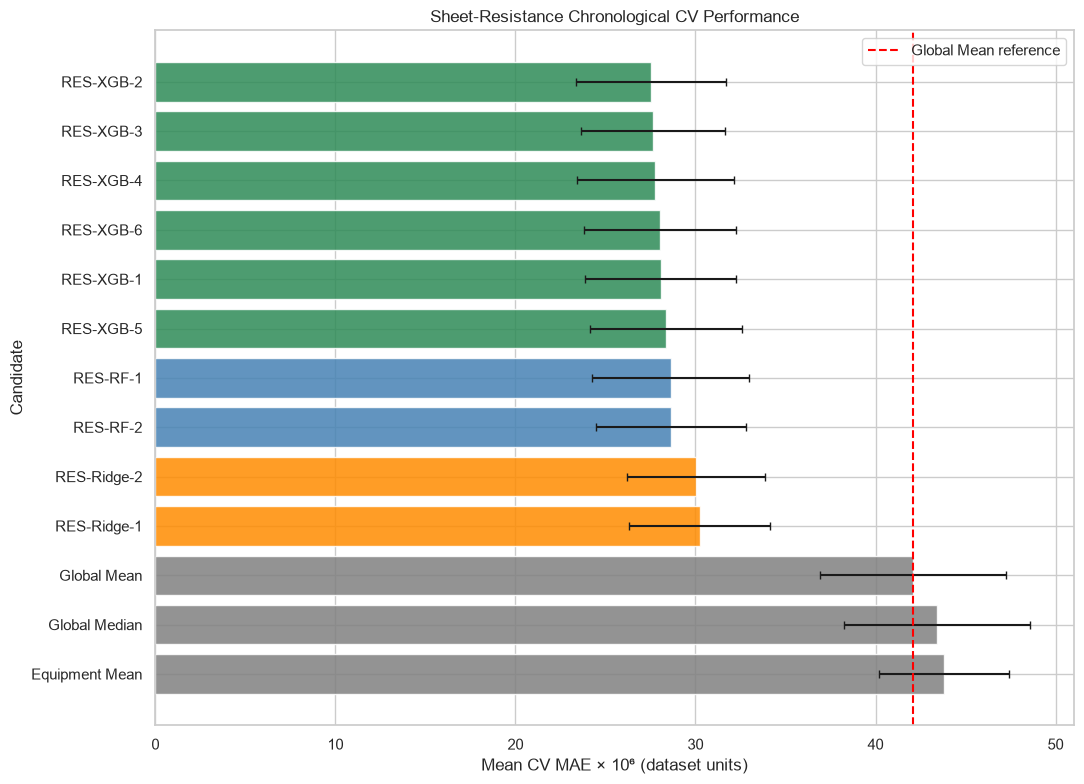

In [13]:

# Resistance model comparison

plot_df = cv_summary.copy()

plot_df["Display MAE"] = (
    plot_df["Mean_CV_MAE"]
    * DISPLAY_SCALE
)

plot_df["Display Std"] = (
    plot_df["Std_CV_MAE"]
    * DISPLAY_SCALE
)

algorithm_colors = {
    "Global Mean": "grey",
    "Global Median": "grey",
    "Equipment Mean": "grey",
    "Ridge": "darkorange",
    "Random Forest": "steelblue",
    "XGBoost": "seagreen",
}

fig, ax = plt.subplots(
    figsize=(11, 8)
)

ax.barh(
    plot_df["Candidate"],

    plot_df["Display MAE"],

    xerr=plot_df["Display Std"],

    color=[
        algorithm_colors[algorithm]

        for algorithm in plot_df["Algorithm"]
    ],

    capsize=3,
    alpha=0.85,
)

ax.axvline(
    best_baseline_mae * DISPLAY_SCALE,

    color="red",

    linestyle="--",

    label=f"{best_baseline_name} reference",
)

ax.invert_yaxis()

ax.set_title(
    "Sheet-Resistance Chronological CV Performance"
)

ax.set_xlabel(
    "Mean CV MAE × 10⁶ (dataset units)"
)

ax.set_ylabel("Candidate")

ax.legend()

plt.tight_layout()
plt.show()

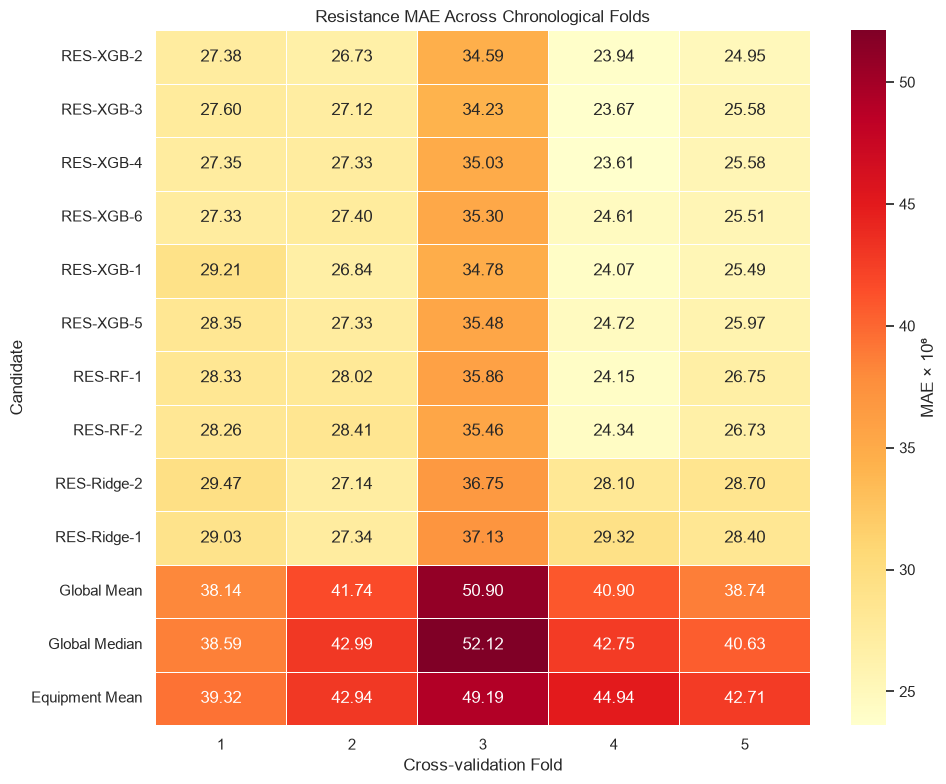

In [14]:

# Resistance fold-level MAE heatmap

fold_mae_matrix = (
    cv_results_df.pivot(
        index="Candidate",

        columns="Fold",

        values="MAE",
    )
    .reindex(
        cv_summary["Candidate"]
    )
    * DISPLAY_SCALE
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    fold_mae_matrix,

    annot=True,

    fmt=".2f",

    cmap="YlOrRd",

    linewidths=0.5,

    cbar_kws={
        "label": "MAE × 10⁶"
    },
)

plt.title(
    "Resistance MAE Across Chronological Folds"
)

plt.xlabel("Cross-validation Fold")

plt.ylabel("Candidate")

plt.tight_layout()
plt.show()

,Candidate,Algorithm,Folds,Mean_CV_MAE,Std_CV_MAE,Best_Fold_MAE,Worst_Fold_MAE,Mean_CV_RMSE,Mean_CV_R2,Mean_CV_MAPE,Mean_Bias,Mean_Training_MAE,Mean_Generalisation_Gap,Maximum_Absolute_Error,Non_Positive_Predictions,Mean_Training_Time,Improvement_vs_Baseline_Pct
0,RES-XGB-2,XGBoost,5,0.000028,0.000004,0.000024,0.000035,0.000041,0.454675,0.940529,-0.000004,0.000009,0.000018,0.000356,0,4.204427,34.606541
1,RES-RF-1,Random Forest,5,0.000029,0.000004,0.000024,0.000036,0.000042,0.423968,0.978137,-0.000006,0.000008,0.000020,0.000348,0,1.839319,31.982959
2,RES-Ridge-2,Ridge,5,0.000030,0.000004,0.000027,0.000037,0.000043,0.378886,1.027917,-0.000002,0.000022,0.000008,0.000360,0,0.068524,28.635697


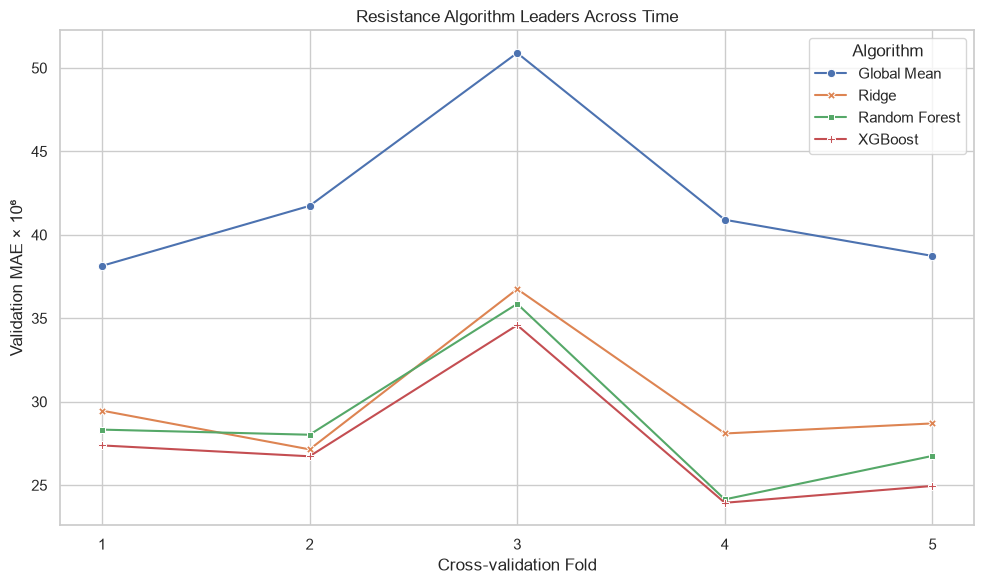

In [15]:

# Select eligible candidates for comparison

eligible_cv_summary = cv_summary.loc[
    (
        cv_summary[
            "Non_Positive_Predictions"
        ] == 0
    )

    &

    (
        cv_summary["Folds"]
        == N_SPLITS
    )
].copy()

ml_eligible = eligible_cv_summary.loc[
    ~eligible_cv_summary["Algorithm"]
    .isin(BASELINE_ALGORITHMS)
].copy()

assert not ml_eligible.empty

family_leaders = (
    ml_eligible
    .sort_values([
        "Mean_CV_MAE",
        "Std_CV_MAE",
        "Candidate",
    ])
    .groupby(
        "Algorithm",
        sort=False,
        as_index=False,
    )
    .head(1)
    .reset_index(drop=True)
)

leader_names = [
    best_baseline_name,
    *family_leaders["Candidate"].tolist(),
]

leader_fold_results = (
    cv_results_df.loc[
        cv_results_df["Candidate"]
        .isin(leader_names)
    ]
    .copy()
)

leader_fold_results["Display MAE"] = (
    leader_fold_results["MAE"]
    * DISPLAY_SCALE
)

display(
    family_leaders.round(10)
)

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=leader_fold_results,

    x="Fold",

    y="Display MAE",

    hue="Algorithm",

    style="Algorithm",

    markers=True,

    dashes=False,

    errorbar=None,
)

plt.xticks(
    range(1, N_SPLITS + 1)
)

plt.title(
    "Resistance Algorithm Leaders Across Time"
)

plt.xlabel("Cross-validation Fold")

plt.ylabel("Validation MAE × 10⁶")

plt.tight_layout()
plt.show()

## 8. XGBoost Early Stopping and Input Ablation

Investigate resistance-specific boosting-round
selection across chronological folds.

Compare matched candidates with and without
explicit equipment metadata.

Compare median imputation with missingness
indicators against native missing-value handling.

The comparisons are descriptive model-development
results rather than statistical superiority tests.

,Minimum_Rounds,Median_Rounds,Maximum_Rounds,Mean_Rounds,Folds_Reaching_Budget
Candidate,,,,,
RES-XGB-1,220.0,799.0,1500.0,857.2,1
RES-XGB-2,452.0,837.0,1367.0,936.2,0
RES-XGB-3,464.0,701.0,1500.0,951.4,2
RES-XGB-4,409.0,718.0,1498.0,797.8,1
RES-XGB-5,219.0,459.0,1038.0,553.6,0
RES-XGB-6,269.0,341.0,588.0,377.2,0


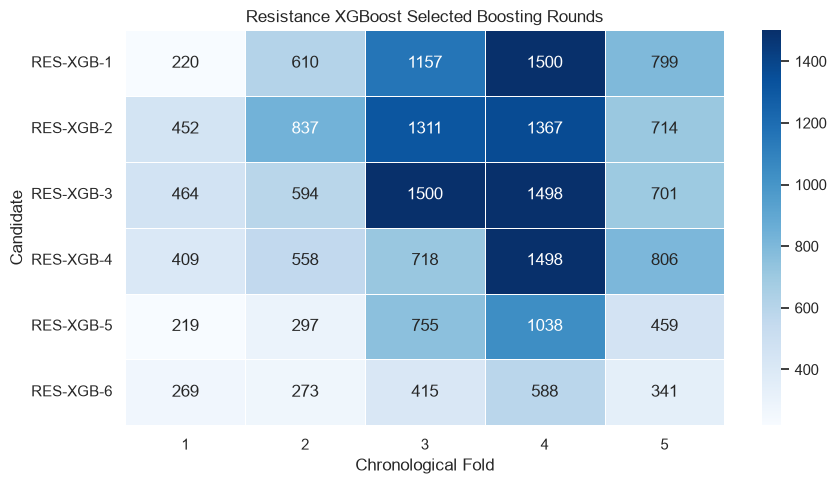

In [16]:

# Resistance-specific selected boosting rounds

xgb_cv_results = (
    cv_results_df.loc[
        cv_results_df["Algorithm"]
        == "XGBoost"
    ]
    .copy()
)

assert len(xgb_cv_results) == 30

assert (
    xgb_cv_results[
        "selected_boosting_rounds"
    ].notna().all()
)

xgb_round_summary = (
    xgb_cv_results
    .groupby("Candidate")
    .agg(
        Minimum_Rounds=(
            "selected_boosting_rounds", "min"
        ),

        Median_Rounds=(
            "selected_boosting_rounds", "median"
        ),

        Maximum_Rounds=(
            "selected_boosting_rounds", "max"
        ),

        Mean_Rounds=(
            "selected_boosting_rounds", "mean"
        ),

        Folds_Reaching_Budget=(
            "boosting_budget_reached", "sum"
        ),
    )
)

display(
    xgb_round_summary.round(3)
)

round_matrix = xgb_cv_results.pivot(
    index="Candidate",

    columns="Fold",

    values="selected_boosting_rounds",
)

plt.figure(figsize=(9, 5))

sns.heatmap(
    round_matrix,

    annot=True,

    fmt=".0f",

    cmap="Blues",

    linewidths=0.5,
)

plt.title(
    "Resistance XGBoost Selected Boosting Rounds"
)

plt.xlabel("Chronological Fold")

plt.ylabel("Candidate")

plt.tight_layout()
plt.show()

In [17]:

# Compare matched equipment configurations

equipment_pairs = [
    (
        "Bounded Ridge",
        "RES-Ridge-1",
        "RES-Ridge-2",
    ),
    (
        "Random Forest",
        "RES-RF-1",
        "RES-RF-2",
    ),
    (
        "XGBoost Median",
        "RES-XGB-1",
        "RES-XGB-2",
    ),
    (
        "XGBoost Native",
        "RES-XGB-3",
        "RES-XGB-4",
    ),
]

mae_lookup = cv_summary.set_index(
    "Candidate"
)["Mean_CV_MAE"]

equipment_rows = []

for label, only_name, equipment_name in (
    equipment_pairs
):

    only_mae = float(
        mae_lookup[only_name]
    )

    equipment_mae = float(
        mae_lookup[equipment_name]
    )

    equipment_rows.append({
        "Configuration": label,

        "APC Only MAE": only_mae,

        "APC + Equipment MAE": equipment_mae,

        "Equipment Improvement (%)": (
            calculate_mae_improvement(
                only_mae,
                equipment_mae,
            )
        ),
    })

equipment_ablation = pd.DataFrame(
    equipment_rows
)

display(
    equipment_ablation.round(10)
)

,Configuration,APC Only MAE,APC + Equipment MAE,Equipment Improvement (%)
0,Bounded Ridge,0.000030,0.000030,0.700387
1,Random Forest,0.000029,0.000029,-0.052044
2,XGBoost Median,0.000028,0.000028,1.988536
3,XGBoost Native,0.000028,0.000028,-0.497305


In [18]:

# Compare complete missing-value strategies

missing_pairs = [
    (
        "APC Only",
        "RES-XGB-1",
        "RES-XGB-3",
    ),
    (
        "APC + Equipment",
        "RES-XGB-2",
        "RES-XGB-4",
    ),
]

missing_rows = []

for label, median_name, native_name in (
    missing_pairs
):

    median_mae = float(
        mae_lookup[median_name]
    )

    native_mae = float(
        mae_lookup[native_name]
    )

    missing_rows.append({
        "Configuration": label,

        "Median MAE": median_mae,

        "Native MAE": native_mae,

        "Native Improvement (%)": (
            calculate_mae_improvement(
                median_mae,
                native_mae,
            )
        ),
    })

missing_ablation = pd.DataFrame(
    missing_rows
)

display(
    missing_ablation.round(10)
)

,Configuration,Median MAE,Native MAE,Native Improvement (%)
0,APC Only,0.000028,0.000028,1.553604
1,APC + Equipment,0.000028,0.000028,-0.943268


## 9. Resistance Model Selection

Select the eligible machine learning candidate
with the lowest mean chronological CV MAE.

Use fold standard deviation and candidate
identifier as deterministic tie-breakers.

For XGBoost, determine a fixed boosting-round
count using the median of the five internally
selected round counts.

Freeze the candidate configuration before
original-validation assessment.

Preserve the strongest historical baseline
and the leading candidate from each model family.

In [19]:

# Select the accuracy-leading resistance candidate

selected_cv_row = (
    ml_eligible
    .sort_values([
        "Mean_CV_MAE",
        "Std_CV_MAE",
        "Candidate",
    ])
    .iloc[0]
)

selected_name = selected_cv_row[
    "Candidate"
]

selected_candidate = candidate_lookup[
    selected_name
]

selected_cv_mae = float(
    selected_cv_row["Mean_CV_MAE"]
)

selected_cv_improvement = (
    calculate_mae_improvement(
        best_baseline_mae,
        selected_cv_mae,
    )
)

print(
    "Selected resistance candidate:",
    selected_name
)

print(
    "Algorithm:",
    selected_candidate["algorithm"]
)

print(
    "Mean CV MAE:",
    f"{selected_cv_mae:.8e}"
)

print(
    "Mean CV RMSE:",
    f"{selected_cv_row['Mean_CV_RMSE']:.8e}"
)

print(
    "Mean CV R2:",
    selected_cv_row["Mean_CV_R2"]
)

print(
    "Improvement over strongest baseline:",
    f"{selected_cv_improvement:.4f}%"
)

if selected_cv_improvement <= 0:

    print(
        "\nWARNING: No positive MAE improvement "
        "over the strongest historical baseline."
    )

Selected resistance candidate: RES-XGB-2
Algorithm: XGBoost
Mean CV MAE: 2.75193029e-05
Mean CV RMSE: 4.06111475e-05
Mean CV R2: 0.45467530633238934
Improvement over strongest baseline: 34.6065%


In [20]:

# Freeze the leading model configurations

def freeze_resistance_candidate(name):

    candidate = candidate_lookup[name]

    frozen = {
        "name": candidate["name"],

        "algorithm": candidate["algorithm"],

        "include_equipment": candidate[
            "include_equipment"
        ],

        "parameters": candidate[
            "parameters"
        ].copy(),
    }

    if frozen["algorithm"] == "XGBoost":

        rounds = (
            xgb_cv_results.loc[
                xgb_cv_results["Candidate"] == name,

                "selected_boosting_rounds",
            ]
            .to_numpy(dtype=float)
        )

        assert len(rounds) == N_SPLITS

        assert np.isfinite(rounds).all()

        frozen["parameters"][
            "n_estimators"
        ] = int(
            np.median(rounds)
        )

    return frozen


assessment_names = list(
    dict.fromkeys(
        leader_names + [selected_name]
    )
)

frozen_candidates = {
    name: freeze_resistance_candidate(name)

    for name in assessment_names
}

frozen_selected_candidate = (
    frozen_candidates[selected_name]
)

print(
    "Frozen resistance-model configuration:"
)

print(
    json.dumps(
        frozen_selected_candidate,
        indent=4,
    )
)

print(
    "\nFrozen candidates for comparative assessment:"
)

display(
    pd.json_normalize(
        list(frozen_candidates.values())
    )
)

Frozen resistance-model configuration:
{
    "name": "RES-XGB-2",
    "algorithm": "XGBoost",
    "include_equipment": true,
    "parameters": {
        "missing_strategy": "median",
        "max_depth": 4,
        "learning_rate": 0.025,
        "n_estimators": 837,
        "min_child_weight": 5,
        "reg_alpha": 0.1,
        "reg_lambda": 5.0,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "gamma": 0.0,
        "random_state": 42
    }
}

Frozen candidates for comparative assessment:


,name,algorithm,include_equipment,parameters.missing_strategy,parameters.max_depth,parameters.learning_rate,parameters.n_estimators,parameters.min_child_weight,parameters.reg_alpha,parameters.reg_lambda,parameters.subsample,parameters.colsample_bytree,parameters.gamma,parameters.random_state,parameters.min_samples_leaf,parameters.max_features,parameters.alpha,parameters.clip_z
0,Global Mean,Global Mean,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,RES-XGB-2,XGBoost,True,median,4.0,0.025,837.0,5.0,0.1,5.0,0.8,0.8,0.0,42.0,NaN,NaN,NaN,NaN
2,RES-RF-1,Random Forest,False,NaN,NaN,NaN,200.0,NaN,NaN,NaN,NaN,NaN,NaN,42.0,1.0,0.7,NaN,NaN
3,RES-Ridge-2,Ridge,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,5.0


In [21]:

# Save the frozen resistance-model selection

results_dir.mkdir(
    parents=True,
    exist_ok=True,
)

selection_path = (
    results_dir
    / "resistance_model_selection.json"
)

selection_record = {
    "project": "STRATUM",

    "target": TARGET,

    "dataset_sha256": current_sha256,

    "selection_partition": (
        "original_training_chronological_cv"
    ),

    "primary_metric": "Mean CV MAE",

    "selection_policy": (
        "Minimum eligible mean chronological CV MAE"
    ),

    "target_transform": {
        "method": "StandardScaler",

        "fit_scope": "Training targets only",

        "inverse_transform_predictions": True,

        "applies_to": "ML candidates",

        "baseline_target_transform": None,
    },

    "boosting_round_policy": (
        "Median internally selected CV boosting rounds"
    ),

    "selected_candidate": (
        frozen_selected_candidate
    ),

    "family_leader_candidates": (
        frozen_candidates
    ),

    "selected_mean_cv_mae": (
        selected_cv_mae
    ),

    "selected_std_cv_mae": float(
        selected_cv_row["Std_CV_MAE"]
    ),

    "selected_mean_cv_rmse": float(
        selected_cv_row["Mean_CV_RMSE"]
    ),

    "selected_mean_cv_r2": float(
        selected_cv_row["Mean_CV_R2"]
    ),

    "best_baseline": best_baseline_name,

    "baseline_mean_cv_mae": (
        best_baseline_mae
    ),

    "selected_improvement_pct": (
        selected_cv_improvement
    ),

    "cv_folds": N_SPLITS,
}

selection_path.write_text(
    json.dumps(
        selection_record,

        indent=4,

        allow_nan=False,
    ),

    encoding="utf-8",
)

print(
    "Frozen resistance configuration saved:"
)

print(
    "ml/results/resistance_model_selection.json"
)

Frozen resistance configuration saved:
ml/results/resistance_model_selection.json


## 10. Frozen Candidate Fitting and Benchmarking

Refit the frozen candidate configurations on
the eligible original training observations.

Use fixed boosting-round counts for XGBoost.

Measure estimated serialized pipeline size,
training time, and repeated prediction latency.

Include automatic inverse target transformation
in inference benchmarking.

Use historical training inputs for timing.

In [22]:

# Refit and benchmark frozen resistance candidates

def measure_latency(
    model,
    inputs,
    repetitions=20,
    warmup=3,
):

    for _ in range(warmup):

        model.predict(inputs)

    timings = []

    for _ in range(repetitions):

        start = time.perf_counter()

        model.predict(inputs)

        timings.append(
            (
                time.perf_counter() - start
            ) * 1000
        )

    return {
        "median_ms": float(
            np.median(timings)
        ),

        "p95_ms": float(
            np.quantile(timings, 0.95)
        ),
    }


benchmark_batch = (
    assessment_train_df
    .sample(
        n=min(
            256,
            len(assessment_train_df),
        ),

        random_state=RANDOM_STATE,
    )
)

fitted_models = {}

deployment_rows = []

for name, candidate in (
    frozen_candidates.items()
):

    columns = get_resistance_candidate_columns(
        candidate,
        apc_features,
    )

    fixed_rounds = (
        candidate["parameters"].get(
            "n_estimators"
        )

        if candidate["algorithm"] == "XGBoost"

        else None
    )

    start = time.perf_counter()

    model, fit_info = (
        fit_resistance_candidate(
            candidate=candidate,

            training_data=assessment_train_df,

            apc_features=apc_features,

            target=TARGET,

            n_jobs=N_JOBS,

            fixed_boosting_rounds=fixed_rounds,
        )
    )

    training_seconds = (
        time.perf_counter() - start
    )

    serialized_bytes = len(
        pickle.dumps(
            model,
            protocol=pickle.HIGHEST_PROTOCOL,
        )
    )

    single_latency = measure_latency(
        model,

        benchmark_batch[columns].iloc[[0]],

        repetitions=30,
    )

    batch_latency = measure_latency(
        model,

        benchmark_batch[columns],

        repetitions=20,
    )

    fitted_models[name] = model

    deployment_rows.append({
        "Candidate": name,

        "Algorithm": candidate["algorithm"],

        "Fixed Boosting Rounds": fixed_rounds,

        "Serialized Size (Bytes)": (
            serialized_bytes
        ),

        "Serialized Size (MiB)": (
            serialized_bytes / 1024**2
        ),

        "Training Time (s)": training_seconds,

        "Single Median Latency (ms)": (
            single_latency["median_ms"]
        ),

        "Single P95 Latency (ms)": (
            single_latency["p95_ms"]
        ),

        "Batch Median Latency (ms)": (
            batch_latency["median_ms"]
        ),

        "Batch P95 Latency (ms)": (
            batch_latency["p95_ms"]
        ),

        "Batch Records": len(benchmark_batch),
    })

    print(
        f"{name}: "
        f"{serialized_bytes / 1024**2:.6f} MiB"
    )

deployment_benchmarks = pd.DataFrame(
    deployment_rows
)

display(
    deployment_benchmarks.round(6)
)

Global Mean: 0.000444 MiB


c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun R

RES-XGB-2: 1.271667 MiB


c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun R

RES-RF-1: 57.631420 MiB


c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun R

RES-Ridge-2: 0.013270 MiB


c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun R

,Candidate,Algorithm,Fixed Boosting Rounds,Serialized Size (Bytes),Serialized Size (MiB),Training Time (s),Single Median Latency (ms),Single P95 Latency (ms),Batch Median Latency (ms),Batch P95 Latency (ms),Batch Records
0,Global Mean,Global Mean,NaN,466,0.000444,0.002113,0.01300,0.015665,0.01370,0.018095,256
1,RES-XGB-2,XGBoost,837.0,1333440,1.271667,1.958672,6.54530,7.244655,10.24835,17.486415,256
2,RES-RF-1,Random Forest,NaN,60430924,57.631420,2.821602,47.17085,53.468620,47.30635,67.246650,256
3,RES-Ridge-2,Ridge,NaN,13915,0.013270,0.924428,4.00710,4.182040,4.53360,6.385745,256


In [23]:

# Verify that the selected model survives serialization

selected_model = fitted_models[
    selected_name
]

selected_columns = (
    get_resistance_candidate_columns(
        frozen_selected_candidate,
        apc_features,
    )
)

verification_inputs = (
    benchmark_batch[selected_columns]
    .iloc[:20]
)

before_serialization = (
    selected_model.predict(
        verification_inputs
    )
)

serialized_model = pickle.dumps(
    selected_model,
    protocol=pickle.HIGHEST_PROTOCOL,
)

restored_model = pickle.loads(
    serialized_model
)

after_serialization = (
    restored_model.predict(
        verification_inputs
    )
)

np.testing.assert_allclose(
    before_serialization,

    after_serialization,

    rtol=1e-10,

    atol=1e-15,
)

print(
    "Resistance pipeline serialization check: PASSED"
)

print(
    "Target inverse transformation preserved."
)

del restored_model
del serialized_model

Resistance pipeline serialization check: PASSED
Target inverse transformation preserved.


c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun R

## 11. Post-Selection Original-Validation Assessment

Evaluate the frozen resistance-model configuration
and leading competing candidates on the original
chronological validation partition.

Calculate all regression metrics using predictions
in the original target scale.

Investigate physical plausibility, tail errors,
prediction bias, and baseline improvement.

Do not modify the frozen selection solely because
another candidate performs better on the original
validation partition.

In [35]:

# Evaluate frozen resistance models

assessment_rows = []

assessment_predictions = {}

y_val = val_df[TARGET].to_numpy(
    dtype=float
)

assert np.isfinite(y_val).all()

assert (y_val > 0).all()

training_target_min = float(
    assessment_train_df[TARGET].min()
)

training_target_max = float(
    assessment_train_df[TARGET].max()
)

for name, model in fitted_models.items():

    candidate = frozen_candidates[name]

    columns = get_resistance_candidate_columns(
        candidate,
        apc_features,
    )

    predictions = np.asarray(
        model.predict(
            val_df[columns]
        )
    )

    assert (
        predictions.shape
        == y_val.shape
    )

    assert np.isfinite(
        predictions
    ).all()

    metrics = evaluate_regression(
        y_val,
        predictions,
    )

    absolute_errors = np.abs(
        y_val - predictions
    )

    assessment_rows.append({
        "Candidate": name,

        "Algorithm": candidate["algorithm"],

        "Validation Records": len(y_val),

        **metrics,

        "P50 Absolute Error": float(
            np.quantile(absolute_errors, 0.50)
        ),

        "P90 Absolute Error": float(
            np.quantile(absolute_errors, 0.90)
        ),

        "P95 Absolute Error": float(
            np.quantile(absolute_errors, 0.95)
        ),

        "P99 Absolute Error": float(
            np.quantile(absolute_errors, 0.99)
        ),

        "Maximum Absolute Error": float(
            absolute_errors.max()
        ),

        "Non-Positive Predictions": int(
            (predictions <= 0).sum()
        ),

        "Outside Training Target Range": int(
            (
                (predictions < training_target_min)

                |

                (predictions > training_target_max)
            ).sum()
        ),
    })

    assessment_predictions[name] = (
        predictions
    )

assessment_results = (
    pd.DataFrame(assessment_rows)
    .merge(
        cv_summary[
            [
                "Candidate",
                "Mean_CV_MAE",
                "Std_CV_MAE",
            ]
        ],

        on="Candidate",

        validate="one_to_one",
    )
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(
    assessment_results.round(10)
)

selected_assessment = (
    assessment_results.loc[
        assessment_results["Candidate"]
        == selected_name
    ].iloc[0]
)

selected_predictions = (
    assessment_predictions[selected_name]
)

assert (
    selected_assessment[
        "Non-Positive Predictions"
    ] == 0
), "Selected resistance model failed positivity check."

assessment_baseline_mae = float(
    assessment_results.loc[
        assessment_results["Candidate"]
        == best_baseline_name,

        "MAE",
    ].iloc[0]
)

validation_improvement = (
    calculate_mae_improvement(
        assessment_baseline_mae,

        float(selected_assessment["MAE"]),
    )
)

print(
    "\nSelected resistance candidate:",
    selected_name
)

print(
    "Original-validation MAE:",
    f"{selected_assessment['MAE']:.8e}"
)

print(
    "Original-validation RMSE:",
    f"{selected_assessment['RMSE']:.8e}"
)

print(
    "Original-validation R2:",
    selected_assessment["R2"]
)

print(
    "Original-validation MAPE:",
    f"{selected_assessment['MAPE (%)']:.6f}%"
)

print(
    "Validation improvement over "
    "CV-selected baseline:",
    f"{validation_improvement:.4f}%"
)


c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun R

,Candidate,Algorithm,Validation Records,MAE,RMSE,R2,MAPE (%),Bias,P50 Absolute Error,P90 Absolute Error,P95 Absolute Error,P99 Absolute Error,Maximum Absolute Error,Non-Positive Predictions,Outside Training Target Range,Mean_CV_MAE,Std_CV_MAE
0,RES-XGB-2,XGBoost,834,0.000023,0.000031,0.633802,0.777569,-2.111000e-07,0.000017,0.000046,0.000062,0.000103,0.000198,0,0,0.000028,0.000004
1,RES-RF-1,Random Forest,834,0.000025,0.000034,0.567325,0.857225,-2.600500e-06,0.000020,0.000050,0.000068,0.000113,0.000219,0,0,0.000029,0.000004
2,RES-Ridge-2,Ridge,834,0.000028,0.000037,0.494302,0.965765,1.335100e-06,0.000022,0.000059,0.000072,0.000103,0.000177,0,0,0.000030,0.000004
3,Global Mean,Global Mean,834,0.000044,0.000055,-0.107464,1.490578,-1.705880e-05,0.000038,0.000087,0.000103,0.000135,0.000247,0,0,0.000042,0.000005



Selected resistance candidate: RES-XGB-2
Original-validation MAE: 2.26635238e-05
Original-validation RMSE: 3.14902640e-05
Original-validation R2: 0.633802264930349
Original-validation MAPE: 0.777569%
Validation improvement over CV-selected baseline: 48.0736%


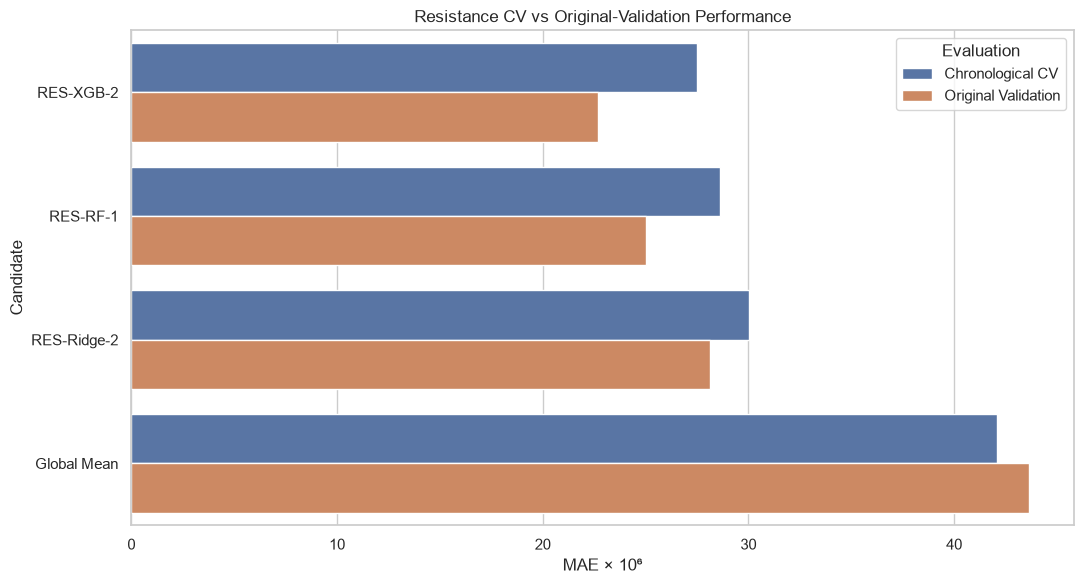

In [26]:

# Compare CV and original-validation performance

assessment_plot_df = (
    assessment_results.melt(
        id_vars=["Candidate"],

        value_vars=[
            "Mean_CV_MAE",
            "MAE",
        ],

        var_name="Evaluation",

        value_name="Error",
    )
)

assessment_plot_df["Evaluation"] = (
    assessment_plot_df["Evaluation"]
    .map({
        "Mean_CV_MAE": "Chronological CV",
        "MAE": "Original Validation",
    })
)

assessment_plot_df["Display MAE"] = (
    assessment_plot_df["Error"]
    * DISPLAY_SCALE
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=assessment_plot_df,

    x="Display MAE",

    y="Candidate",

    hue="Evaluation",
)

plt.title(
    "Resistance CV vs Original-Validation Performance"
)

plt.xlabel("MAE × 10⁶")

plt.ylabel("Candidate")

plt.tight_layout()
plt.show()

## 12. Selected Resistance Prediction Diagnostics

Investigate actual versus predicted resistance,
residual distributions, cumulative absolute
errors, and equipment-specific prediction bias.

All diagnostics use the original-validation
observations after model selection.

Positive prediction values are a basic
plausibility requirement, not proof of
manufacturing specification compliance.

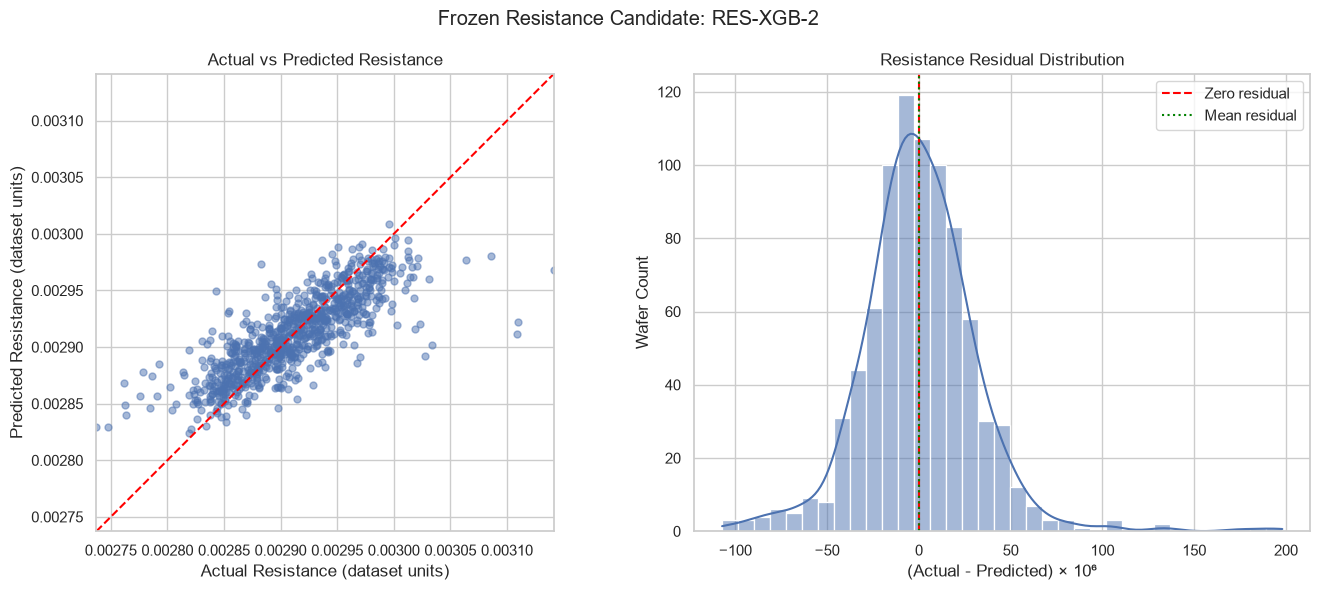

In [27]:

# Resistance prediction and residual diagnostics

residuals = (
    y_val - selected_predictions
)

lower = min(
    y_val.min(),
    selected_predictions.min(),
)

upper = max(
    y_val.max(),
    selected_predictions.max(),
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6),
)

axes[0].scatter(
    y_val,

    selected_predictions,

    alpha=0.5,

    s=25,
)

axes[0].plot(
    [lower, upper],

    [lower, upper],

    color="red",

    linestyle="--",
)

axes[0].set_xlim(lower, upper)

axes[0].set_ylim(lower, upper)

axes[0].set_aspect(
    "equal",
    adjustable="box",
)

axes[0].set_title(
    "Actual vs Predicted Resistance"
)

axes[0].set_xlabel(
    "Actual Resistance (dataset units)"
)

axes[0].set_ylabel(
    "Predicted Resistance (dataset units)"
)

sns.histplot(
    residuals * DISPLAY_SCALE,

    bins=35,

    kde=True,

    ax=axes[1],
)

axes[1].axvline(
    0,

    color="red",

    linestyle="--",

    label="Zero residual",
)

axes[1].axvline(
    residuals.mean() * DISPLAY_SCALE,

    color="green",

    linestyle=":",

    label="Mean residual",
)

axes[1].set_title(
    "Resistance Residual Distribution"
)

axes[1].set_xlabel(
    "(Actual - Predicted) × 10⁶"
)

axes[1].set_ylabel("Wafer Count")

axes[1].legend()

fig.suptitle(
    f"Frozen Resistance Candidate: {selected_name}"
)

plt.tight_layout()
plt.show()

,Percentile,Absolute Error,Error × 10⁶
0,P50,0.000017,17.175121
1,P90,0.000046,45.606156
2,P95,0.000062,61.556744
3,P99,0.000103,102.582077
4,P100,0.000198,197.976932


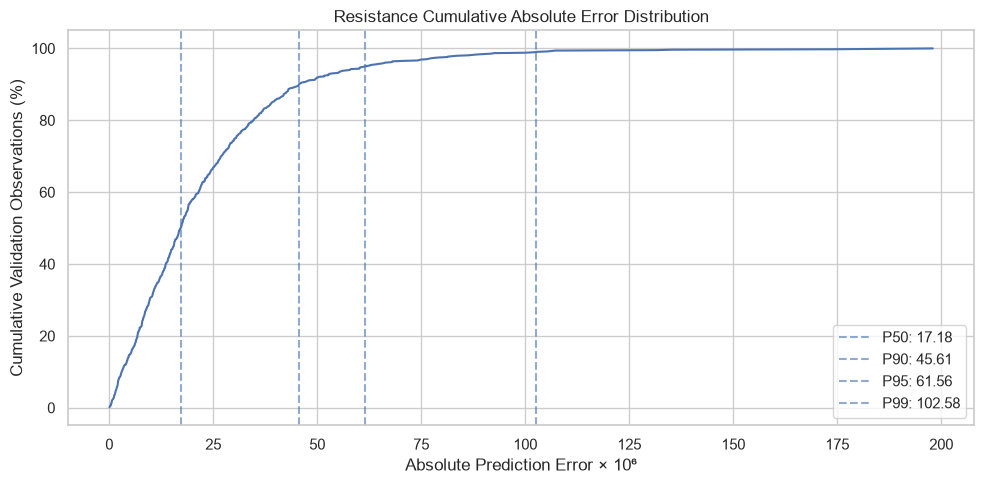

In [28]:

# Resistance cumulative absolute error distribution

absolute_errors = np.abs(
    y_val - selected_predictions
)

sorted_errors = np.sort(
    absolute_errors
)

cumulative_percentage = (
    np.arange(
        1,
        len(sorted_errors) + 1,
    )
    / len(sorted_errors)
    * 100
)

error_percentiles = {
    f"P{percentile}": float(
        np.percentile(
            absolute_errors,
            percentile,
        )
    )

    for percentile in [
        50, 90, 95, 99, 100
    ]
}

display(
    pd.DataFrame([
        {
            "Percentile": label,

            "Absolute Error": value,

            "Error × 10⁶": (
                value * DISPLAY_SCALE
            ),
        }

        for label, value
        in error_percentiles.items()
    ])
)

plt.figure(figsize=(10, 5))

plt.plot(
    sorted_errors * DISPLAY_SCALE,

    cumulative_percentage,
)

for label in [
    "P50",
    "P90",
    "P95",
    "P99",
]:

    value = (
        error_percentiles[label]
        * DISPLAY_SCALE
    )

    plt.axvline(
        value,

        linestyle="--",

        alpha=0.6,

        label=f"{label}: {value:.2f}",
    )

plt.title(
    "Resistance Cumulative Absolute Error Distribution"
)

plt.xlabel("Absolute Prediction Error × 10⁶")

plt.ylabel(
    "Cumulative Validation Observations (%)"
)

plt.legend()

plt.tight_layout()
plt.show()

,Records,MAE,Bias,Maximum_Error,RMSE
equipment,,,,,
equipment_16,47,0.000033,-0.000033,0.000084,0.000038
equipment_1,56,0.000031,0.000020,0.000174,0.000040
equipment_11,50,0.000030,-0.000005,0.000102,0.000040
equipment_3,47,0.000026,0.000014,0.000106,0.000036
equipment_15,50,0.000025,-0.000003,0.000198,0.000041
equipment_14,56,0.000025,0.000015,0.000105,0.000033
equipment_13,54,0.000025,-0.000022,0.000060,0.000029
equipment_8,54,0.000023,-0.000005,0.000135,0.000031
equipment_7,48,0.000023,0.000006,0.000088,0.000031


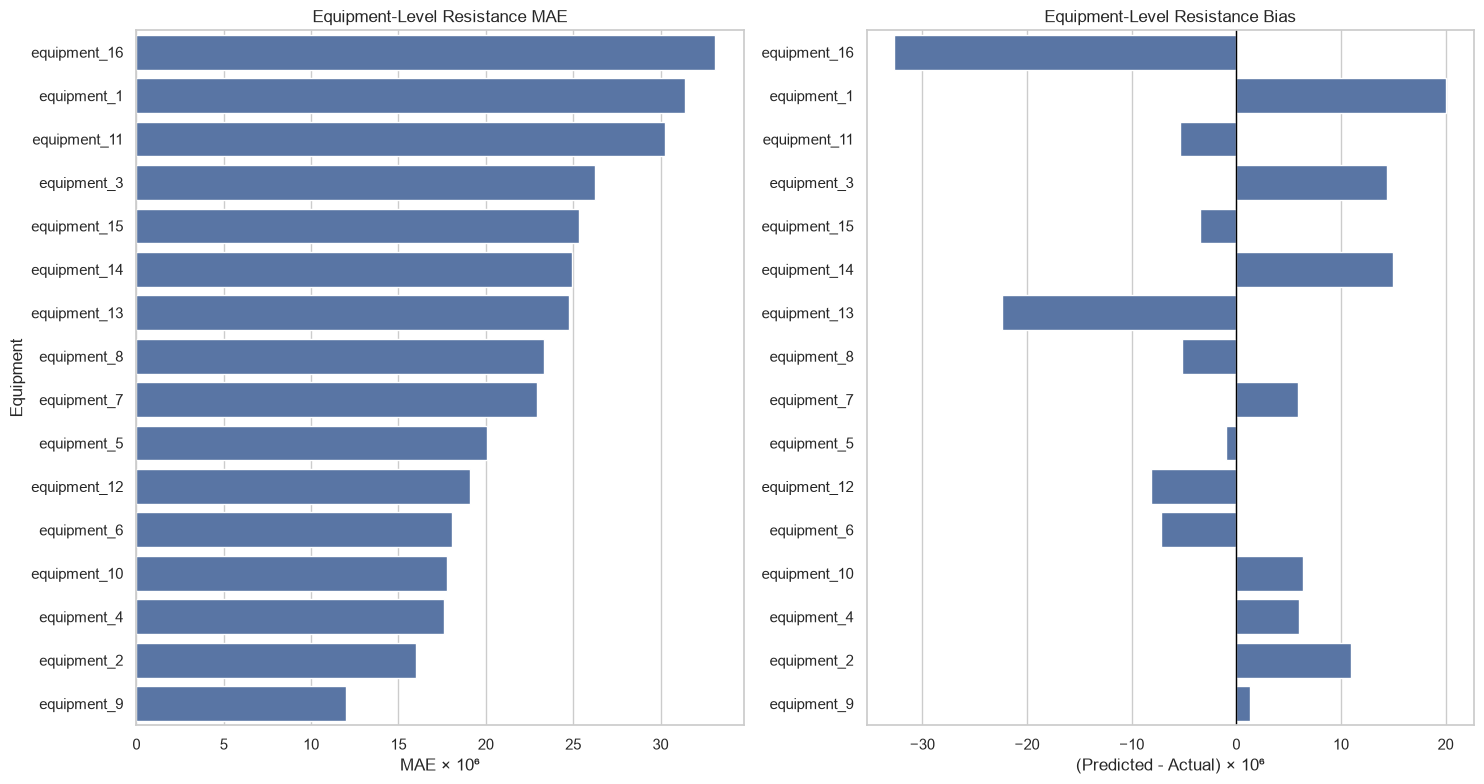

In [29]:

# Resistance equipment-level performance

equipment_errors = pd.DataFrame({
    "equipment": (
        val_df["equipment"].to_numpy()
    ),

    "Actual": y_val,

    "Predicted": selected_predictions,
})

equipment_errors["Bias"] = (
    equipment_errors["Predicted"]

    - equipment_errors["Actual"]
)

equipment_errors["Absolute Error"] = (
    equipment_errors["Bias"].abs()
)

equipment_errors["Squared Error"] = (
    equipment_errors["Bias"] ** 2
)

equipment_summary = (
    equipment_errors
    .groupby("equipment")
    .agg(
        Records=("Actual", "count"),

        MAE=("Absolute Error", "mean"),

        MSE=("Squared Error", "mean"),

        Bias=("Bias", "mean"),

        Maximum_Error=(
            "Absolute Error", "max"
        ),
    )
)

equipment_summary["RMSE"] = np.sqrt(
    equipment_summary.pop("MSE")
)

equipment_summary = (
    equipment_summary
    .sort_values(
        "MAE",
        ascending=False,
    )
)

display(
    equipment_summary.round(10)
)

equipment_plot_df = (
    equipment_summary.reset_index()
)

equipment_plot_df["Display MAE"] = (
    equipment_plot_df["MAE"]
    * DISPLAY_SCALE
)

equipment_plot_df["Display Bias"] = (
    equipment_plot_df["Bias"]
    * DISPLAY_SCALE
)

equipment_order = (
    equipment_plot_df["equipment"]
    .tolist()
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 8),
)

sns.barplot(
    data=equipment_plot_df,

    x="Display MAE",

    y="equipment",

    order=equipment_order,

    ax=axes[0],
)

sns.barplot(
    data=equipment_plot_df,

    x="Display Bias",

    y="equipment",

    order=equipment_order,

    ax=axes[1],
)

axes[1].axvline(
    0,
    color="black",
    linewidth=1,
)

axes[0].set_title(
    "Equipment-Level Resistance MAE"
)

axes[1].set_title(
    "Equipment-Level Resistance Bias"
)

axes[0].set_xlabel("MAE × 10⁶")

axes[1].set_xlabel(
    "(Predicted - Actual) × 10⁶"
)

axes[0].set_ylabel("Equipment")

axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## 13. Multi-Parameter Virtual Metrology Comparison

Compare the independently selected thickness
and resistance virtual metrology configurations.

Use R2, MAPE, and relative baseline improvement
to contextualise predictive performance across
targets with different numerical magnitudes.

Do not directly compare raw thickness and
resistance MAE values as if they shared a scale.

The comparison is based on model-development
results, not final held-out performance.

,Target,Candidate,Algorithm,Equipment Input,Target Standardised,Mean CV MAE,CV Baseline Improvement (%),Validation MAE,Validation RMSE,Validation R2,Validation MAPE (%)
0,Thickness,XGB-4,XGBoost,False,False,1.209290,38.462110,1.072550,1.443448,0.650733,0.706370
1,Sheet Resistance,RES-XGB-2,XGBoost,True,True,0.000028,34.606541,0.000023,0.000031,0.633802,0.777569


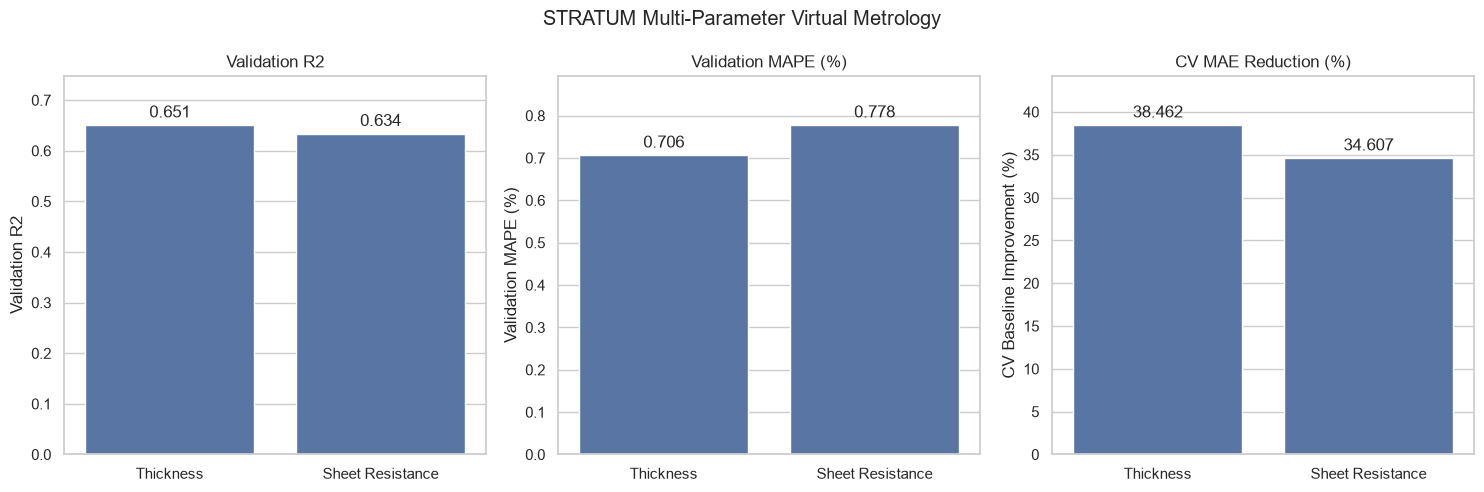

In [30]:

# Retrieve frozen thickness assessment results

thickness_candidate_name = (
    thickness_selection[
        "selected_candidate"
    ]["name"]
)

thickness_assessment_df = pd.DataFrame(
    thickness_optimisation[
        "assessment_results"
    ]
)

thickness_assessment = (
    thickness_assessment_df.loc[
        thickness_assessment_df["Candidate"]
        == thickness_candidate_name
    ].iloc[0]
)

thickness_cv_baseline = float(
    thickness_selection[
        "baseline_mean_cv_mae"
    ]
)

thickness_cv_mae = float(
    thickness_selection[
        "selected_mean_cv_mae"
    ]
)

thickness_cv_improvement = (
    calculate_mae_improvement(
        thickness_cv_baseline,
        thickness_cv_mae,
    )
)

dual_target_comparison = pd.DataFrame([
    {
        "Target": "Thickness",

        "Candidate": thickness_candidate_name,

        "Algorithm": (
            thickness_selection[
                "selected_candidate"
            ]["algorithm"]
        ),

        "Equipment Input": (
            thickness_selection[
                "selected_candidate"
            ]["include_equipment"]
        ),

        "Target Standardised": False,

        "Mean CV MAE": thickness_cv_mae,

        "CV Baseline Improvement (%)": (
            thickness_cv_improvement
        ),

        "Validation MAE": float(
            thickness_assessment["MAE"]
        ),

        "Validation RMSE": float(
            thickness_assessment["RMSE"]
        ),

        "Validation R2": float(
            thickness_assessment["R2"]
        ),

        "Validation MAPE (%)": float(
            thickness_assessment["MAPE (%)"]
        ),
    },
    {
        "Target": "Sheet Resistance",

        "Candidate": selected_name,

        "Algorithm": (
            frozen_selected_candidate["algorithm"]
        ),

        "Equipment Input": (
            frozen_selected_candidate[
                "include_equipment"
            ]
        ),

        "Target Standardised": True,

        "Mean CV MAE": selected_cv_mae,

        "CV Baseline Improvement (%)": (
            selected_cv_improvement
        ),

        "Validation MAE": float(
            selected_assessment["MAE"]
        ),

        "Validation RMSE": float(
            selected_assessment["RMSE"]
        ),

        "Validation R2": float(
            selected_assessment["R2"]
        ),

        "Validation MAPE (%)": float(
            selected_assessment["MAPE (%)"]
        ),
    },
])

display(
    dual_target_comparison.round(10)
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5),
)

for ax, metric, title in [
    (
        axes[0],
        "Validation R2",
        "Validation R2",
    ),
    (
        axes[1],
        "Validation MAPE (%)",
        "Validation MAPE (%)",
    ),
    (
        axes[2],
        "CV Baseline Improvement (%)",
        "CV MAE Reduction (%)",
    ),
]:

    sns.barplot(
        data=dual_target_comparison,

        x="Target",

        y=metric,

        ax=ax,
    )

    ax.bar_label(
        ax.containers[0],

        fmt="%.3f",

        padding=3,
    )

    ax.set_title(title)

    ax.set_xlabel("")

    ax.margins(y=0.15)

plt.suptitle(
    "STRATUM Multi-Parameter Virtual Metrology"
)

plt.tight_layout()
plt.show()

## 14. Resistance Inference Robustness Checks

Verify prediction behaviour with:

- Ordinary historical process inputs.
- Additional missing APC measurements.
- An unknown equipment identifier, where relevant.
- Combined missing measurements and unknown equipment.

These are synthetic input-handling checks.

Successful numerical predictions do not establish
accuracy for missing or unfamiliar manufacturing
conditions.

In [31]:

# Resistance inference robustness smoke tests

ordinary_input = (
    assessment_train_df[selected_columns]
    .iloc[[0]]
    .copy()
)

missing_input = ordinary_input.copy()

# Select three currently observed sensor values.

available_features = [
    feature

    for feature in apc_features

    if feature in missing_input.columns

    and pd.notna(
        missing_input.iloc[0][feature]
    )
]

assert len(available_features) >= 3

synthetically_missing_features = (
    available_features[:3]
)

for feature in synthetically_missing_features:

    missing_input[feature] = np.nan

inference_cases = {
    "Ordinary Input": ordinary_input,

    "Three Additional Missing Sensors": (
        missing_input
    ),
}

if frozen_selected_candidate[
    "include_equipment"
]:

    unknown_equipment_input = (
        ordinary_input.copy()
    )

    unknown_equipment_input["equipment"] = (
        "equipment_unseen_test"
    )

    combined_input = missing_input.copy()

    combined_input["equipment"] = (
        "equipment_unseen_test"
    )

    inference_cases.update({
        "Unknown Equipment": (
            unknown_equipment_input
        ),

        "Missing Sensors + Unknown Equipment": (
            combined_input
        ),
    })

robustness_rows = []

for label, inputs in inference_cases.items():

    prediction = np.asarray(
        selected_model.predict(inputs)
    )

    assert prediction.shape == (1,)

    assert np.isfinite(prediction).all()

    robustness_rows.append({
        "Scenario": label,

        "Prediction": float(prediction[0]),

        "Finite": bool(
            np.isfinite(prediction[0])
        ),

        "Positive": bool(
            prediction[0] > 0
        ),
    })

robustness_results = pd.DataFrame(
    robustness_rows
)

display(
    robustness_results.round(10)
)

print(
    "Artificially missing sensors:",
    synthetically_missing_features
)

if not frozen_selected_candidate[
    "include_equipment"
]:

    print(
        "Unknown equipment check not applicable: "
        "selected model uses APC-only inputs."
    )

if robustness_results["Positive"].all():

    print(
        "Resistance inference smoke checks: PASSED"
    )

else:

    print(
        "WARNING: Non-positive synthetic-input "
        "prediction requires investigation."
    )

c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\Tarun R

,Scenario,Prediction,Finite,Positive
0,Ordinary Input,0.002885,True,True
1,Three Additional Missing Sensors,0.002890,True,True
2,Unknown Equipment,0.002885,True,True
3,Missing Sensors + Unknown Equipment,0.002890,True,True


Artificially missing sensors: ['AMPS_TARGET_20_90_DELTA_DEP1', 'AMPS_TARGET_20_90_DEP1_M', 'AMPS_TARGET_20_90_DEP1_X']
Resistance inference smoke checks: PASSED


## 15. Resistance Experiment Integrity Verification

Verify candidate-fold completeness, out-of-fold
prediction alignment, target-scaling parameters,
chronological separation, and boosting-round
validity.

Confirm that the saved resistance configuration
matches the selected candidate.

The final test partition remains reserved.

In [32]:

# Verify complete resistance experiment integrity

assert len(candidates) == 13

assert len(cv_results_df) == 65

assert len(cv_summary) == 13

assert len(xgb_cv_results) == 30

assert (
    cv_summary["Folds"] == N_SPLITS
).all()

assert not cv_results_df[
    ["Candidate", "Fold"]
].duplicated().any()

assert np.isfinite(
    cv_results_df[
        [
            "MAE",
            "RMSE",
            "R2",
            "Bias",
        ]
    ].to_numpy()
).all()

# Verify aligned out-of-fold predictions.

expected_oof_count = (
    len(candidates)
    * len(all_cv_validation_ids)
)

assert len(
    oof_predictions_df
) == expected_oof_count

assert not oof_predictions_df[
    ["Candidate", "wafer_id"]
].duplicated().any()

reference_ids = set(
    all_cv_validation_ids
)

for name, group in (
    oof_predictions_df.groupby("Candidate")
):

    assert set(
        group["wafer_id"]
    ) == reference_ids

    assert np.isfinite(
        group["Predicted"]
    ).all()


# Verify training-target scaling metadata.

for fold in folds:

    fold_number = fold["fold"]

    fold_target = fold["train"][TARGET]

    fold_ml_results = cv_results_df.loc[
        (
            cv_results_df["Fold"]
            == fold_number
        )

        &

        (
            ~cv_results_df["Algorithm"]
            .isin(BASELINE_ALGORITHMS)
        )
    ]

    assert fold_ml_results[
        "target_standardised"
    ].all()

    np.testing.assert_allclose(
        fold_ml_results[
            "target_training_mean"
        ],

        fold_target.mean(),

        rtol=1e-12,
    )

    np.testing.assert_allclose(
        fold_ml_results[
            "target_training_std"
        ],

        fold_target.std(ddof=0),

        rtol=1e-12,
    )


# Verify XGBoost selected round counts.

for _, row in xgb_cv_results.iterrows():

    candidate = candidate_lookup[
        row["Candidate"]
    ]

    budget = candidate["parameters"][
        "n_estimators"
    ]

    assert (
        1
        <= row["selected_boosting_rounds"]
        <= budget
    )


# Verify the fitted selected target transformer.

np.testing.assert_allclose(
    selected_model.transformer_.mean_[0],

    assessment_train_df[TARGET].mean(),

    rtol=1e-12,
)

np.testing.assert_allclose(
    selected_model.transformer_.scale_[0],

    assessment_train_df[TARGET].std(ddof=0),

    rtol=1e-12,
)


# Verify the frozen selection.

saved_selection = json.loads(
    selection_path.read_text(
        encoding="utf-8"
    )
)

assert (
    saved_selection["selected_candidate"]
    == frozen_selected_candidate
)

assert (
    saved_selection["dataset_sha256"]
    == current_sha256
)

assert (
    saved_selection["selected_candidate"]["name"]
    == selected_name
)

assert (
    selected_assessment[
        "Non-Positive Predictions"
    ] == 0
)

print(
    "Resistance experiment integrity: PASSED"
)

print(
    "Verified candidate-fold evaluations:",
    len(cv_results_df)
)

print(
    "Verified OOF predictions:",
    len(oof_predictions_df)
)

print(
    "Training-target scaling: VERIFIED"
)

print(
    "Frozen resistance configuration: VERIFIED"
)

print(
    "Reserved final test targets not evaluated."
)

Resistance experiment integrity: PASSED
Verified candidate-fold evaluations: 65
Verified OOF predictions: 25935
Training-target scaling: VERIFIED
Frozen resistance configuration: VERIFIED
Reserved final test targets not evaluated.


## 16. Resistance Experiment Result Preservation

Preserve the candidate configurations,
cross-validation metrics, early-stopping
diagnostics, equipment and missingness
ablations, deployment benchmarks, and
original-validation assessment results.

Store numerical metrics in the original
resistance target scale.

Preserve full floating-point precision.

Do not export individual wafer records or
permanent fitted model artifacts.

In [33]:

# Preserve resistance optimisation results

import platform
import os


def dataframe_to_json_records(frame):

    return (
        frame.astype(object)
        .where(pd.notna(frame), None)
        .to_dict(orient="records")
    )


def json_default(value):

    if isinstance(value, np.generic):

        return value.item()

    if isinstance(value, pd.Timestamp):

        return value.isoformat()

    raise TypeError(
        f"Unsupported JSON type: "
        f"{type(value).__name__}"
    )


resistance_results = {
    "project": "STRATUM",

    "experiment": "resistance_optimisation",

    "target": TARGET,

    "dataset_sha256": current_sha256,

    "selection_partition": (
        "original_training_chronological_cv"
    ),

    "assessment_partition": (
        "original_validation"
    ),

    "training_records": len(train_df),

    "assessment_training_records": len(
        assessment_train_df
    ),

    "validation_records": len(val_df),

    "cv_method": (
        "Chronological expanding-window CV "
        "with lot and batch purging"
    ),

    "cv_folds": N_SPLITS,

    "initial_train_fraction": (
        INITIAL_TRAIN_FRACTION
    ),

    "inner_validation_fraction": (
        INNER_VALIDATION_FRACTION
    ),

    "early_stopping_rounds": (
        EARLY_STOPPING_ROUNDS
    ),

    "random_state": RANDOM_STATE,

    "n_jobs": N_JOBS,

    "sklearn_version": sklearn.__version__,

    "xgboost_version": xgboost.__version__,

    "target_transform": (
        selection_record["target_transform"]
    ),

    "metric_target_scale": (
        "Original dataset target scale"
    ),

    "plot_error_display_multiplier": (
        DISPLAY_SCALE
    ),

    "primary_metric": "Mean CV MAE",

    "candidate_count": len(candidates),

    "completed_fold_evaluations": len(
        cv_results_df
    ),

    "oof_records_per_candidate": len(
        all_cv_validation_ids
    ),

    "search_elapsed_seconds": float(
        search_elapsed
    ),

    "best_baseline": best_baseline_name,

    "baseline_mean_cv_mae": (
        best_baseline_mae
    ),

    "candidates": candidates,

    "fold_summary": fold_summary,

    "assessment_purge_info": (
        assessment_purge_info
    ),

    "target_fold_summary": (
        dataframe_to_json_records(
            target_fold_summary
        )
    ),

    "fold_results": (
        dataframe_to_json_records(
            cv_results_df
        )
    ),

    "cv_summary": (
        dataframe_to_json_records(
            cv_summary
        )
    ),

    "pooled_oof_metrics": (
        dataframe_to_json_records(
            pooled_metrics_df
        )
    ),

    "xgboost_round_summary": (
        dataframe_to_json_records(
            xgb_round_summary.reset_index()
        )
    ),

    "family_leaders": (
        dataframe_to_json_records(
            family_leaders
        )
    ),

    "equipment_ablation": (
        dataframe_to_json_records(
            equipment_ablation
        )
    ),

    "missing_strategy_ablation": (
        dataframe_to_json_records(
            missing_ablation
        )
    ),

    "deployment_benchmarks": (
        dataframe_to_json_records(
            deployment_benchmarks
        )
    ),

    "benchmark_environment": {
        "platform": platform.platform(),

        "processor": platform.processor(),

        "logical_cpu_count": os.cpu_count(),

        "n_jobs": N_JOBS,

        "single_record_repetitions": 30,

        "batch_repetitions": 20,

        "warmup_repetitions": 3,

        "batch_records": len(benchmark_batch),
    },

    "selection": selection_record,

    "selected_candidate": (
        frozen_selected_candidate
    ),

    "selected_mean_cv_mae": (
        selected_cv_mae
    ),

    "selected_cv_improvement_pct": (
        selected_cv_improvement
    ),

    "selected_validation_mae": float(
        selected_assessment["MAE"]
    ),

    "selected_validation_rmse": float(
        selected_assessment["RMSE"]
    ),

    "selected_validation_r2": float(
        selected_assessment["R2"]
    ),

    "selected_validation_mape": float(
        selected_assessment["MAPE (%)"]
    ),

    "selected_validation_bias": float(
        selected_assessment["Bias"]
    ),

    "validation_improvement_pct": (
        validation_improvement
    ),

    "assessment_results": (
        dataframe_to_json_records(
            assessment_results
        )
    ),

    "error_percentiles": error_percentiles,

    "equipment_error_summary": (
        dataframe_to_json_records(
            equipment_summary.reset_index()
        )
    ),

    "dual_target_comparison": (
        dataframe_to_json_records(
            dual_target_comparison
        )
    ),

    "synthetic_missing_features": (
        synthetically_missing_features
    ),

    "inference_robustness_results": (
        dataframe_to_json_records(
            robustness_results
        )
    ),

    "limitations": [
        "Candidate configurations informed by "
        "preceding thickness experiments.",

        "Target standardisation is a predefined "
        "numerical modelling decision.",

        "A separate unscaled-target ablation "
        "was not performed.",

        "Cross-validation scores were used "
        "for candidate selection.",

        "Chronological folds are not independent.",

        "Fixed median boosting rounds differ "
        "from fold-adaptive configurations.",

        "Synthetic robustness checks do not "
        "establish predictive accuracy.",

        "Equipment and temporal shifts remain.",

        "Local computational timings do not "
        "represent production API latency.",

        "Official engineering acceptance "
        "thresholds and measurement units "
        "are not established.",

        "Measured quality is distinct from "
        "predicted material properties.",

        "Final held-out test targets "
        "were not evaluated.",
    ],
}

results_path = (
    results_dir
    / "resistance_optimisation.json"
)

with open(
    results_path,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        resistance_results,

        file,

        indent=4,

        allow_nan=False,

        default=json_default,
    )

saved_results = json.loads(
    results_path.read_text(
        encoding="utf-8"
    )
)

assert (
    saved_results["candidate_count"]
    == 13
)

assert (
    saved_results[
        "completed_fold_evaluations"
    ]
    == 65
)

assert (
    saved_results["selected_candidate"]
    == frozen_selected_candidate
)

assert (
    saved_results["dataset_sha256"]
    == current_sha256
)

assert (
    saved_results["selection"]
    == selection_record
)

print("Resistance experiment results saved.")

print(
    "ml/results/resistance_optimisation.json"
)

print(
    "\nExperiment JSON verification: PASSED"
)

Resistance experiment results saved.
ml/results/resistance_optimisation.json

Experiment JSON verification: PASSED


## 17. Final Resistance Experiment Summary

Generate a consolidated summary of resistance
candidate selection, cross-validation performance,
original-validation assessment, computational
benchmarking, and multi-parameter comparison.

In [34]:

# Consolidated resistance research summary

print("=" * 65)

print("STRATUM - SHEET RESISTANCE VIRTUAL METROLOGY")

print("=" * 65)

print("\nEXPERIMENT DESIGN")

print("Candidates:", len(candidates))

print("Chronological folds:", len(folds))

print(
    "Completed evaluations:",
    len(cv_results_df)
)

print(
    "OOF records per candidate:",
    len(all_cv_validation_ids)
)

print(
    "Search duration:",
    round(search_elapsed, 2),
    "seconds"
)

print("\nHISTORICAL BASELINE")

print("Best baseline:", best_baseline_name)

print(
    f"Mean CV MAE: "
    f"{best_baseline_mae:.8e}"
)

print("\nSELECTED RESISTANCE MODEL")

print("Candidate:", selected_name)

print(
    "Algorithm:",
    frozen_selected_candidate["algorithm"]
)

print(
    "Equipment input:",
    frozen_selected_candidate[
        "include_equipment"
    ]
)

print(
    "Parameters:",
    frozen_selected_candidate["parameters"]
)

print("Target standardisation: StandardScaler")

print(
    f"Mean CV MAE: "
    f"{selected_cv_mae:.8e}"
)

print(
    f"CV MAE standard deviation: "
    f"{selected_cv_row['Std_CV_MAE']:.8e}"
)

print(
    f"Mean CV RMSE: "
    f"{selected_cv_row['Mean_CV_RMSE']:.8e}"
)

print(
    f"Mean CV R2: "
    f"{selected_cv_row['Mean_CV_R2']:.6f}"
)

print(
    f"Worst-fold MAE: "
    f"{selected_cv_row['Worst_Fold_MAE']:.8e}"
)

print(
    f"CV baseline improvement: "
    f"{selected_cv_improvement:.4f}%"
)

print("\nORIGINAL-VALIDATION PERFORMANCE")

for metric in [
    "MAE",
    "RMSE",
    "Bias",
    "P95 Absolute Error",
    "Maximum Absolute Error",
]:

    print(
        f"{metric}: "
        f"{selected_assessment[metric]:.8e}"
    )

print(
    f"R2: "
    f"{selected_assessment['R2']:.6f}"
)

print(
    f"MAPE: "
    f"{selected_assessment['MAPE (%)']:.6f}%"
)

print(
    f"Baseline MAE improvement: "
    f"{validation_improvement:.4f}%"
)

print(
    "Non-positive predictions:",
    selected_assessment[
        "Non-Positive Predictions"
    ]
)

print("\nDEPLOYMENT BENCHMARK")

selected_benchmark = (
    deployment_benchmarks.loc[
        deployment_benchmarks["Candidate"]
        == selected_name
    ].iloc[0]
)

print(
    "Serialized size (MiB):",
    selected_benchmark[
        "Serialized Size (MiB)"
    ]
)

print(
    "Single median latency (ms):",
    selected_benchmark[
        "Single Median Latency (ms)"
    ]
)

print(
    "Batch median latency (ms):",
    selected_benchmark[
        "Batch Median Latency (ms)"
    ]
)

print("\nMULTI-PARAMETER VIRTUAL METROLOGY")

display(
    dual_target_comparison.round(10)
)

print("\nRESEARCH STATUS")

print(
    "Thickness configuration: FROZEN"
)

print(
    "Resistance configuration: FROZEN"
)

print(
    "Final held-out evaluation: PENDING"
)

print("=" * 65)

STRATUM - SHEET RESISTANCE VIRTUAL METROLOGY

EXPERIMENT DESIGN
Candidates: 13
Chronological folds: 5
Completed evaluations: 65
OOF records per candidate: 1995
Search duration: 130.25 seconds

HISTORICAL BASELINE
Best baseline: Global Mean
Mean CV MAE: 4.20826540e-05

SELECTED RESISTANCE MODEL
Candidate: RES-XGB-2
Algorithm: XGBoost
Equipment input: True
Parameters: {'missing_strategy': 'median', 'max_depth': 4, 'learning_rate': 0.025, 'n_estimators': 837, 'min_child_weight': 5, 'reg_alpha': 0.1, 'reg_lambda': 5.0, 'subsample': 0.8, 'colsample_bytree': 0.8, 'gamma': 0.0, 'random_state': 42}
Target standardisation: StandardScaler
Mean CV MAE: 2.75193029e-05
CV MAE standard deviation: 4.18288117e-06
Mean CV RMSE: 4.06111475e-05
Mean CV R2: 0.454675
Worst-fold MAE: 3.45885372e-05
CV baseline improvement: 34.6065%

ORIGINAL-VALIDATION PERFORMANCE
MAE: 2.26635238e-05
RMSE: 3.14902640e-05
Bias: -2.11061147e-07
P95 Absolute Error: 6.15567440e-05
Maximum Absolute Error: 1.97976932e-04
R2: 0.63

,Target,Candidate,Algorithm,Equipment Input,Target Standardised,Mean CV MAE,CV Baseline Improvement (%),Validation MAE,Validation RMSE,Validation R2,Validation MAPE (%)
0,Thickness,XGB-4,XGBoost,False,False,1.209290,38.462110,1.072550,1.443448,0.650733,0.706370
1,Sheet Resistance,RES-XGB-2,XGBoost,True,True,0.000028,34.606541,0.000023,0.000031,0.633802,0.777569



RESEARCH STATUS
Thickness configuration: FROZEN
Resistance configuration: FROZEN
Final held-out evaluation: PENDING



## 18. Findings and Engineering Interpretation

### Research Motivation

Previous STRATUM investigations demonstrated
that thickness alone is insufficient for
comprehensive wafer quality monitoring.

Of the 335 overall bad-quality observations
in the full dataset, 323 retained a good
thickness classification.

The current investigation extends the virtual
metrology framework to mean sheet resistance.

Thickness and resistance are predicted
independently using eligible process inputs,
without requiring measured metrology targets
as predictive features.

### Experimental Methodology

The original training partition contained
3331 wafer observations.

The same five chronological cross-validation
folds established during thickness optimisation
were reproduced.

Lot and batch overlap protection was preserved.

Experimental scope:

- Historical baseline candidates: 3.
- Bounded Ridge candidates: 2.
- Random Forest candidates: 2.
- XGBoost candidates: 6.
- Total candidates: 13.
- Candidate-fold evaluations: 65.
- OOF observations per candidate: 1995.
- Total OOF predictions: 25935.
- Non-positive OOF predictions: 0.
- Search duration: 130.252663 seconds.

### Target Standardisation

Original training target statistics:

- Mean: 0.002894437510.
- Population standard deviation: 0.000053341697.

ML candidates used a StandardScaler fitted
exclusively on the relevant training targets.

The transformed target had a mean approximately
equal to zero and a population standard
deviation equal to one.

XGBoost early stopping used independent
target scaling within chronological inner
training subsets.

Predictions were automatically inverse-transformed
into the original dataset target scale.

The target transformer is integrated into
the fitted regression pipeline.

Standardisation changes the numerical scale
but does not remove distribution skewness.

An unscaled-target ablation was not performed.
Consequently, improved predictive accuracy
cannot be attributed specifically to scaling.

### Historical Baselines

Mean chronological CV MAE:

- Global Mean: 4.20826540e-05.
- Global Median: 4.34145345e-05.
- Equipment Mean: 4.38190543e-05.

The Global Mean was the strongest historical
resistance baseline.

This differs from the preceding thickness
investigation, where the equipment-mean
baseline was selected.

Equipment-specific historical averages did
not improve mean chronological CV MAE for
sheet resistance.

### Selected Resistance Model

The selected candidate was RES-XGB-2.

Configuration:

- Algorithm: XGBoost.
- Input configuration: APC + Equipment.
- Raw predictive inputs: 111.
- Missing strategy: Median imputation.
- Missingness indicators: Enabled.
- Target transformer: StandardScaler.
- Boosting rounds: 837.
- Maximum tree depth: 4.
- Learning rate: 0.025.
- Minimum child weight: 5.
- L1 regularisation: 0.1.
- L2 regularisation: 5.0.
- Subsample: 0.8.
- Column sampling: 0.8.
- Gamma: 0.0.
- Random state: 42.

### Cross-validation Performance

The selected resistance candidate achieved:

- Mean CV MAE: 2.75193029e-05.
- Fold MAE standard deviation: 4.18288117e-06.
- Mean CV RMSE: 4.06111475e-05.
- Mean CV R2: 0.454675.
- Mean CV MAPE: 0.940529%.
- Mean prediction bias: -4.38263390e-06.
- Mean training MAE: 9.23101863e-06.
- Mean generalisation gap: 1.82882843e-05.
- Worst-fold MAE: 3.45885372e-05.
- Best-fold MAE: 2.39441920e-05.
- Non-positive OOF predictions: 0.

Leading algorithm mean CV MAEs:

- Global Mean: 4.20826540e-05.
- Bounded Ridge: 3.00319925e-05.
- Random Forest: 2.86233759e-05.
- XGBoost: 2.75193029e-05.

RES-XGB-2 reduced mean chronological CV MAE
by 34.606541% relative to the strongest
historical resistance baseline.

All six XGBoost configurations achieved
lower mean CV MAE than the investigated
Random Forest configurations.

These are descriptive model-performance
comparisons rather than formal statistical
superiority tests.

### Temporal Performance

Selected RES-XGB-2 fold MAEs:

- Fold 1: 2.73812662e-05.
- Fold 2: 2.67300156e-05.
- Fold 3: 3.45885372e-05.
- Fold 4: 2.39441920e-05.
- Fold 5: 2.49525036e-05.

The selected XGBoost candidate outperformed
the leading Ridge, Random Forest and Global
Mean configurations in all five folds.

Fold 3 exhibited the highest resistance
prediction MAE and the lowest selected-model R2.

It also exhibited the largest validation
target standard deviation.

The mean validation resistance exceeded
the corresponding training mean in every fold.

Both training and validation target means
increased across successive folds.

These observations indicate temporal target
distribution changes and support the use
of chronological evaluation.

The specific causes of the observed
performance differences remain unknown.

### XGBoost Early Stopping

Selected RES-XGB-2 boosting rounds:

- Fold 1: 452.
- Fold 2: 837.
- Fold 3: 1311.
- Fold 4: 1367.
- Fold 5: 714.

Median selected boosting rounds: 837.

None of the selected RES-XGB-2 early-stopping
fits reached the maximum budget of 1500 rounds.

Across all 30 resistance XGBoost early-stopping
fits, four reached their maximum training budgets.

The frozen resistance model uses 837 rounds.

The round count was selected before
original-validation assessment.

### Equipment Metadata Ablation

Relative mean CV MAE improvement from
including explicit equipment identifiers:

- Bounded Ridge: +0.700387%.
- Random Forest: -0.052044%.
- XGBoost Median: +1.988536%.
- XGBoost Native: -0.497305%.

Equipment metadata did not consistently
improve performance across configurations.

However, the selected resistance configuration
includes equipment identifiers.

This differs from the frozen thickness
configuration, which uses APC-only inputs.

The result supports target-specific
predictor configuration selection.

Equipment-associated predictive information
does not establish causal equipment effects.

### Missing-Value Strategy

Relative mean CV MAE improvement from
native missing-value handling:

- APC Only: +1.553604%.
- APC + Equipment: -0.943268%.

Native missing handling performed better
for the APC-only comparison.

Median imputation with missingness indicators
performed better for the APC-plus-equipment
comparison.

The selected resistance pipeline retains
median imputation and missingness indicators.

The comparison concerns complete preprocessing
strategies rather than isolated imputation effects.

### Original-Validation Assessment

The frozen resistance candidate achieved:

- Validation observations: 834.
- MAE: 2.26635238e-05.
- RMSE: 3.14902640e-05.
- R2: 0.633802.
- MAPE: 0.777569%.
- Signed prediction bias: -2.11061147e-07.
- P95 absolute error: 6.15567440e-05.
- Maximum absolute error: 1.97976932e-04.
- Non-positive predictions: 0.
- Predictions outside training target range: 0.

The selected resistance model reduced
original-validation MAE by 48.073620%
relative to the matched Global Mean baseline.

The selected model also achieved the lowest
original-validation MAE among shortlisted
candidates.

The original validation partition remains
a development-stage assessment population.

Final held-out performance remains unknown.

### Error Distribution

Original-validation absolute error percentiles:

- P50: 1.71751210e-05.
- P90: 4.56061558e-05.
- P95: 6.15567440e-05.
- P99: 1.02582077e-04.
- Maximum: 1.97976932e-04.

Predictions exhibited concentration towards
the central target range.

Some high resistance observations were
underpredicted, while some low resistance
observations were overpredicted.

The reported percentiles are empirical
validation error statistics rather than
calibrated prediction intervals or
engineering acceptance thresholds.

### Equipment-Level Prediction Behaviour

Equipment_16 exhibited the highest
resistance MAE among validation equipment
groups.

Equipment_16 performance:

- Validation observations: 47.
- MAE: 3.31004418e-05.
- RMSE: 3.79483882e-05.
- Signed prediction bias: -3.26745156e-05.
- Maximum absolute error: 8.36391608e-05.

The previously selected thickness model
exhibited positive prediction bias of
+1.701980 for the same equipment group.

The selected resistance model exhibited
systematic underprediction.

These opposing material-property biases
are observational findings.

No common physical cause or equipment
fault has been established.

Equipment_9 achieved the lowest equipment-level
resistance MAE of 1.19889251e-05.

The results support equipment-specific
monitoring alongside aggregate model metrics.

### Deployment Considerations

Selected resistance pipeline:

- Estimated serialized size: 1.271667 MiB.
- Single-record median latency: 6.545300 ms.
- Single-record P95 latency: 7.244655 ms.
- 256-record batch median latency: 10.248350 ms.

The complete pipeline, including the
fitted target transformer, successfully
passed an in-memory serialization and
restoration test.

Local inference measurements include
preprocessing and inverse target transformation.

They do not represent complete production
API response times.

### Inference Robustness

Synthetic scenarios evaluated:

- Ordinary historical input.
- Three additional missing APC values.
- Unknown equipment identifier.
- Combined missing APC values and
  unknown equipment identifier.

All four scenarios returned finite,
positive resistance predictions.

These implementation checks establish
numerical input handling rather than
predictive accuracy under missing or
unfamiliar manufacturing conditions.

### Multi-Parameter Virtual Metrology

Thickness model:

- Candidate: XGB-4.
- Input configuration: APC Only.
- Boosting rounds: 820.
- Validation MAE: 1.072550.
- Validation R2: 0.650733.
- Validation MAPE: 0.706370%.
- CV baseline MAE reduction: 38.462110%.

Resistance model:

- Candidate: RES-XGB-2.
- Input configuration: APC + Equipment.
- Boosting rounds: 837.
- Validation MAE: 2.26635238e-05.
- Validation R2: 0.633802.
- Validation MAPE: 0.777569%.
- CV baseline MAE reduction: 34.606541%.

The two targets use independently selected
predictor configurations and model parameters.

Raw MAE values are not directly comparable
because the targets have different numerical
scales.

The selected models establish a multi-parameter
virtual metrology framework.

They do not independently establish overall
manufacturing quality classification.

### Final Model Selection

The resistance configuration was frozen
before original-validation assessment.

The selected configuration was preserved in:

ml/results/resistance_model_selection.json

The complete experiment was preserved in:

ml/results/resistance_optimisation.json

Both thickness and resistance configurations
will be reused for explainability, final
held-out evaluation and application integration.

### Limitations

- Candidate configurations were informed
  by earlier development experiments.
- Hyperparameter optimisation was focused
  rather than exhaustive.
- Chronological folds are not independent.
- Target standardisation was not independently
  compared against unscaled target training.
- Statistical superiority between algorithms
  has not been established.
- Equipment and temporal shifts remain possible.
- Synthetic robustness checks do not establish
  predictive accuracy.
- Prediction-time APC feature availability
  requires further verification.
- Official physical measurement units and
  engineering acceptance thresholds are
  not established.
- Empirical error percentiles are not calibrated
  prediction intervals.
- Computational measurements are machine-specific.
- Final held-out performance remains unknown.

### Conclusion

The investigation extends STRATUM from
single-property thickness prediction to
independent multi-parameter virtual metrology.

XGBoost emerged as the leading investigated
regression family for both material properties.

The resistance investigation established
target-specific feature selection, historical
baseline evaluation, chronological cross-validation,
training-fitted target standardisation, and
automatic inverse target transformation.

Both virtual metrology configurations
are now frozen.

The next stage investigates model explainability
and prepares both models for final held-out
evaluation.